# Project: Identify Customer Segments

In this project, you will apply unsupervised learning techniques to identify segments of the population that form the core customer base for a mail-order sales company in Germany. These segments can then be used to direct marketing campaigns towards audiences that will have the highest expected rate of returns. The data that you will use has been provided by our partners at Bertelsmann Arvato Analytics, and represents a real-life data science task.

This notebook will help you complete this task by providing a framework within which you will perform your analysis steps. In each step of the project, you will see some text describing the subtask that you will perform, followed by one or more code cells for you to complete your work. **Feel free to add additional code and markdown cells as you go along so that you can explore everything in precise chunks.** The code cells provided in the base template will outline only the major tasks, and will usually not be enough to cover all of the minor tasks that comprise it.

It should be noted that while there will be precise guidelines on how you should handle certain tasks in the project, there will also be places where an exact specification is not provided. **There will be times in the project where you will need to make and justify your own decisions on how to treat the data.** These are places where there may not be only one way to handle the data. In real-life tasks, there may be many valid ways to approach an analysis task. One of the most important things you can do is clearly document your approach so that other scientists can understand the decisions you've made.

At the end of most sections, there will be a Markdown cell labeled **Discussion**. In these cells, you will report your findings for the completed section, as well as document the decisions that you made in your approach to each subtask. **Your project will be evaluated not just on the code used to complete the tasks outlined, but also your communication about your observations and conclusions at each stage.**

In [1]:
import warnings
from dataclasses import dataclass

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

%matplotlib inline
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42


### Step 0: Load the Data

There are four files associated with this project (not including this one):

- `Udacity_AZDIAS_Subset.csv`: Demographics data for the general population of Germany; 891211 persons (rows) x 85 features (columns).
- `Udacity_CUSTOMERS_Subset.csv`: Demographics data for customers of a mail-order company; 191652 persons (rows) x 85 features (columns).
- `AZDIAS_Feature_Summary.csv`: Summary of feature attributes for demographics data; 85 features (rows) x 4 columns.
- `Data_Dictionary.md`: Detailed information file about the features in the provided datasets.

Each row of the demographics files represents a single person, but also includes information outside of individuals, including information about their household, building, and neighborhood. Use the summary file to get a better understanding of what each feature means, in terms of the level of measurement and the codes used for missing / unknown data.

In [2]:
# Load in the general demographics data.
azdias = pd.read_csv('Udacity_AZDIAS_Subset.csv', sep=';')

# Load in the feature summary file.
feat_info = pd.read_csv('AZDIAS_Feature_Summary.csv', sep=';')

In [3]:
# Check the structure of the data after it's loaded.
print('azdias shape:   ', azdias.shape)
print('feat_info shape:', feat_info.shape)
azdias.head()

azdias shape:    (891221, 85)
feat_info shape: (85, 4)


,AGER_TYP,ALTERSKATEGORIE_GROB,ANREDE_KZ,CJT_GESAMTTYP,FINANZ_MINIMALIST,FINANZ_SPARER,FINANZ_VORSORGER,FINANZ_ANLEGER,FINANZ_UNAUFFAELLIGER,FINANZ_HAUSBAUER,...,PLZ8_ANTG1,PLZ8_ANTG2,PLZ8_ANTG3,PLZ8_ANTG4,PLZ8_BAUMAX,PLZ8_HHZ,PLZ8_GBZ,ARBEIT,ORTSGR_KLS9,RELAT_AB
0,-1,2,1,2.0,3,4,3,5,5,3,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,-1,1,2,5.0,1,5,2,5,4,5,...,2.0,3.0,2.0,1.0,1.0,5.0,4.0,3.0,5.0,4.0
2,-1,3,2,3.0,1,4,1,2,3,5,...,3.0,3.0,1.0,0.0,1.0,4.0,4.0,3.0,5.0,2.0
3,2,4,2,2.0,4,2,5,2,1,2,...,2.0,2.0,2.0,0.0,1.0,3.0,4.0,2.0,3.0,3.0
4,-1,3,1,5.0,4,3,4,1,3,2,...,2.0,4.0,2.0,1.0,2.0,3.0,3.0,4.0,6.0,5.0


In [4]:
feat_info.head(10)

,attribute,information_level,type,missing_or_unknown
0,AGER_TYP,person,categorical,"[-1,0]"
1,ALTERSKATEGORIE_GROB,person,ordinal,"[-1,0,9]"
2,ANREDE_KZ,person,categorical,"[-1,0]"
3,CJT_GESAMTTYP,person,categorical,[0]
4,FINANZ_MINIMALIST,person,ordinal,[-1]
5,FINANZ_SPARER,person,ordinal,[-1]
6,FINANZ_VORSORGER,person,ordinal,[-1]
7,FINANZ_ANLEGER,person,ordinal,[-1]
8,FINANZ_UNAUFFAELLIGER,person,ordinal,[-1]
9,FINANZ_HAUSBAUER,person,ordinal,[-1]


In [5]:
azdias.describe()

,AGER_TYP,ALTERSKATEGORIE_GROB,ANREDE_KZ,CJT_GESAMTTYP,FINANZ_MINIMALIST,FINANZ_SPARER,FINANZ_VORSORGER,FINANZ_ANLEGER,FINANZ_UNAUFFAELLIGER,FINANZ_HAUSBAUER,...,PLZ8_ANTG1,PLZ8_ANTG2,PLZ8_ANTG3,PLZ8_ANTG4,PLZ8_BAUMAX,PLZ8_HHZ,PLZ8_GBZ,ARBEIT,ORTSGR_KLS9,RELAT_AB
count,891221.000000,891221.000000,891221.000000,886367.000000,891221.000000,891221.000000,891221.000000,891221.000000,891221.000000,891221.000000,...,774706.000000,774706.000000,774706.000000,774706.000000,774706.000000,774706.000000,774706.000000,794005.000000,794005.000000,794005.00000
mean,-0.358435,2.777398,1.522098,3.632838,3.074528,2.821039,3.401106,3.033328,2.874167,3.075121,...,2.253330,2.801858,1.595426,0.699166,1.943913,3.612821,3.381087,3.167854,5.293002,3.07222
std,1.198724,1.068775,0.499512,1.595021,1.321055,1.464749,1.322134,1.529603,1.486731,1.353248,...,0.972008,0.920309,0.986736,0.727137,1.459654,0.973967,1.111598,1.002376,2.303739,1.36298
min,-1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000,0.000000,1.00000
25%,-1.000000,2.000000,1.000000,2.000000,2.000000,1.000000,3.000000,2.000000,2.000000,2.000000,...,1.000000,2.000000,1.000000,0.000000,1.000000,3.000000,3.000000,3.000000,4.000000,2.00000
50%,-1.000000,3.000000,2.000000,4.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,...,2.000000,3.000000,2.000000,1.000000,1.000000,4.000000,3.000000,3.000000,5.000000,3.00000
75%,-1.000000,4.000000,2.000000,5.000000,4.000000,4.000000,5.000000,5.000000,4.000000,4.000000,...,3.000000,3.000000,2.000000,1.000000,3.000000,4.000000,4.000000,4.000000,7.000000,4.00000
max,3.000000,9.000000,2.000000,6.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,...,4.000000,4.000000,3.000000,2.000000,5.000000,5.000000,5.000000,9.000000,9.000000,9.00000


## Step 1: Preprocessing

### Step 1.1: Assess Missing Data

The feature summary file contains a summary of properties for each demographics data column. You will use this file to make cleaning decisions during this stage of the project.

#### Step 1.1.1: Convert Missing Value Codes to NaNs

The fourth column of the feature summary (`missing_or_unknown`) documents the codes from the data dictionary that indicate missing or unknown data. While the file encodes this as a list (e.g. `[-1,0]`), this will get read in as a string object. We parse those strings into actual lists, and then convert every matching data value into a `NaN` so that missing data is encoded consistently across the whole dataset.

Note that a couple of features (`CAMEO_DEUG_2015`, `CAMEO_DEU_2015`, `CAMEO_INTL_2015`) contain non-numeric codes such as `X` or `XX`, so the parser must keep those as strings. In addition, those columns are read by pandas as `object` dtype, so numeric missing codes may appear as strings in the raw data — we therefore match both the numeric and the string representation of each missing code.

In [6]:
# Identify missing or unknown data values and convert them to NaNs.

def parse_missing_codes(s):
    """Parse a string like '[-1,0]' or '[-1,X]' into a python list."""
    s = s.strip('[]')
    if not s:
        return []
    codes = []
    for v in s.split(','):
        v = v.strip()
        try:
            codes.append(int(v))
        except ValueError:
            codes.append(v)           # keep 'X', 'XX' as strings
    return codes

feat_info['missing_codes'] = feat_info['missing_or_unknown'].apply(parse_missing_codes)
feat_info[['attribute', 'missing_or_unknown', 'missing_codes']].head(8)

,attribute,missing_or_unknown,missing_codes
0,AGER_TYP,"[-1,0]","[-1, 0]"
1,ALTERSKATEGORIE_GROB,"[-1,0,9]","[-1, 0, 9]"
2,ANREDE_KZ,"[-1,0]","[-1, 0]"
3,CJT_GESAMTTYP,[0],[0]
4,FINANZ_MINIMALIST,[-1],[-1]
5,FINANZ_SPARER,[-1],[-1]
6,FINANZ_VORSORGER,[-1],[-1]
7,FINANZ_ANLEGER,[-1],[-1]


In [7]:
def encode_missing_as_nan(df, feat_info):
    """Replace all documented missing/unknown codes with np.nan."""
    df = df.copy()
    for attr, codes in zip(feat_info['attribute'], feat_info['missing_codes']):
        if not codes or attr not in df.columns:
            continue
        # match both numeric codes and their string representation
        # (object-dtype columns store numbers as strings)
        full_codes = codes + [str(c) for c in codes if isinstance(c, int)]
        df[attr] = df[attr].replace(full_codes, np.nan)
    return df

n_nan_before = azdias.isnull().sum().sum()
azdias = encode_missing_as_nan(azdias, feat_info)
n_nan_after = azdias.isnull().sum().sum()

print('NaNs before re-encoding: {:,}'.format(n_nan_before))
print('NaNs after re-encoding:  {:,}'.format(n_nan_after))

NaNs before re-encoding: 4,896,838
NaNs after re-encoding:  8,373,929


#### Step 1.1.2: Assess Missing Data in Each Column

How much missing data is present in each column? Some columns have a lot more missing values than the rest — we visualize the distribution, identify the outlier columns, and remove them from the dataset.

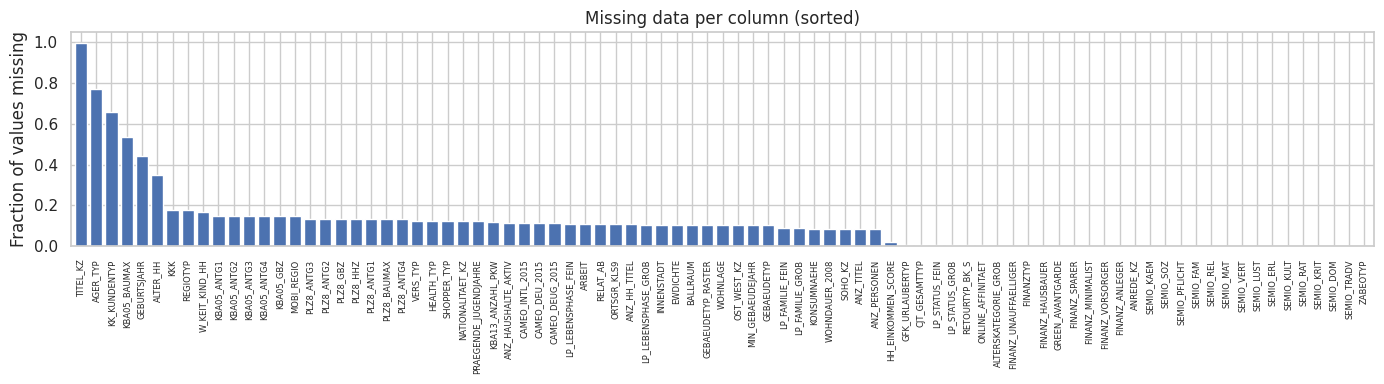

In [8]:
# Perform an assessment of how much missing data there is in each column of the dataset.
col_missing_pct = azdias.isnull().mean().sort_values(ascending=False)

plt.figure(figsize=(14, 4))
col_missing_pct.plot(kind='bar', width=0.8)
plt.ylabel('Fraction of values missing')
plt.title('Missing data per column (sorted)')
plt.xticks(fontsize=6)
plt.tight_layout()
plt.show()

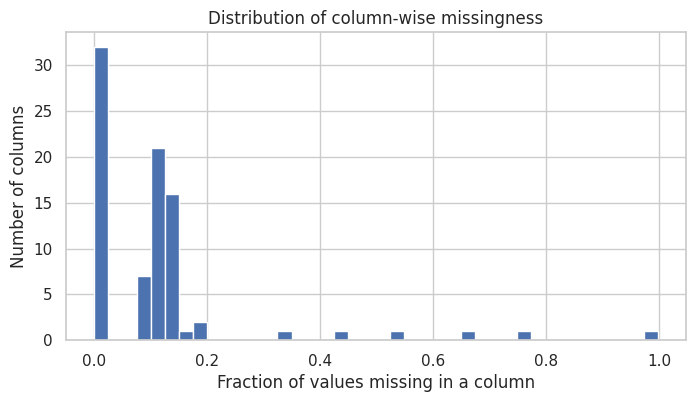

TITEL_KZ          0.997576
AGER_TYP          0.769554
KK_KUNDENTYP      0.655967
KBA05_BAUMAX      0.534687
GEBURTSJAHR       0.440203
ALTER_HH          0.348137
KKK               0.177357
REGIOTYP          0.177357
W_KEIT_KIND_HH    0.166051
KBA05_ANTG1       0.149597
dtype: float64

In [9]:
plt.figure(figsize=(8, 4))
plt.hist(col_missing_pct, bins=40)
plt.xlabel('Fraction of values missing in a column')
plt.ylabel('Number of columns')
plt.title('Distribution of column-wise missingness')
plt.show()

col_missing_pct.head(10)

,mean,min,max
information_level,,,
microcell_rr3,190524.000000,133324,476524
household,183101.714286,18348,584612
macrocell_plz8,115175.625000,105800,116515
region_rr1,109492.200000,4854,158064
microcell_rr4,99352.000000,99352,99352
community,97341.333333,97274,97375
postcode,93740.000000,93740,93740
building,91882.857143,73969,99611
person,68970.395349,0,889061


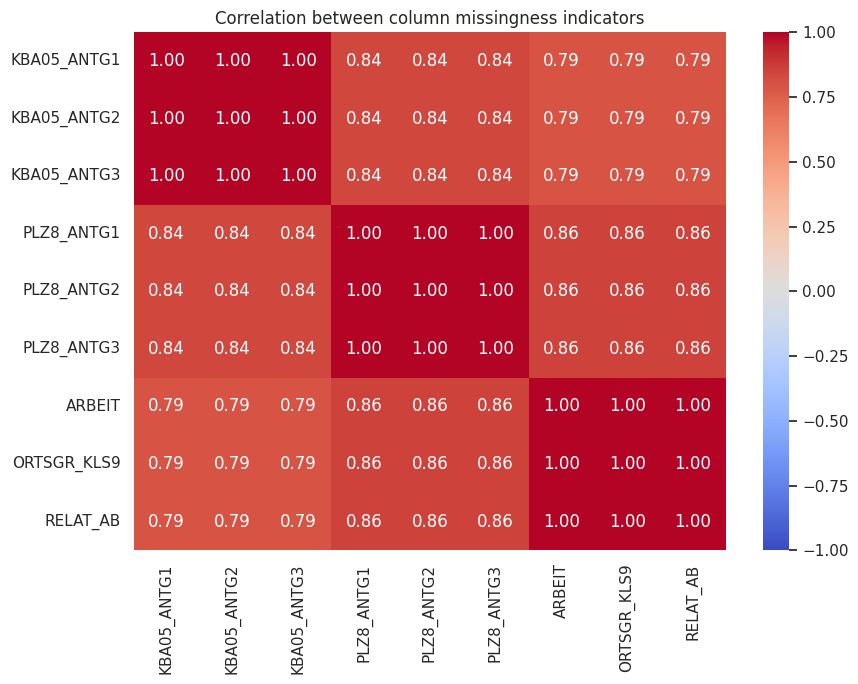

,fraction_with_matching_missingness
KBA05_ANTG1 / KBA05_ANTG2,1.0
PLZ8_ANTG1 / PLZ8_ANTG2,1.0
ARBEIT / RELAT_AB,1.0


In [10]:
col_missing_cnt = azdias.isna().sum()
pattern = (feat_info.set_index('attribute')
           .assign(n_missing=col_missing_cnt)
           .groupby('information_level')['n_missing']
           .agg(['mean', 'min', 'max']))
display(pattern.sort_values('mean', ascending=False))

# Correlate the missingness indicators, not the observed feature values.
pattern_cols = ['KBA05_ANTG1', 'KBA05_ANTG2', 'KBA05_ANTG3',
                'PLZ8_ANTG1', 'PLZ8_ANTG2', 'PLZ8_ANTG3',
                'ARBEIT', 'ORTSGR_KLS9', 'RELAT_AB']
missing_flags = azdias[pattern_cols].isna()
missing_correlations = missing_flags.astype(float).corr()
plt.figure(figsize=(9, 7))
sns.heatmap(missing_correlations, annot=True, fmt='.2f', vmin=-1, vmax=1,
            cmap='coolwarm')
plt.title('Correlation between column missingness indicators')
plt.tight_layout()
plt.show()
pair_agreement = pd.Series({
    f'{a} / {b}': (missing_flags[a] == missing_flags[b]).mean()
    for a, b in [('KBA05_ANTG1', 'KBA05_ANTG2'),
                 ('PLZ8_ANTG1', 'PLZ8_ANTG2'), ('ARBEIT', 'RELAT_AB')]
}, name='fraction_with_matching_missingness')
display(pair_agreement.to_frame())


In [11]:
# Remove the outlier columns from the dataset. (You'll perform other data
# engineering tasks such as re-encoding and imputation later.)
COL_MISSING_THRESHOLD = 0.20
outlier_cols = col_missing_pct[col_missing_pct > COL_MISSING_THRESHOLD].index.tolist()
print('Outlier columns (> {:.0%} missing):'.format(COL_MISSING_THRESHOLD))
print(col_missing_pct[outlier_cols])

azdias = azdias.drop(columns=outlier_cols)
print('\nShape after dropping outlier columns:', azdias.shape)

Outlier columns (> 20% missing):
TITEL_KZ        0.997576
AGER_TYP        0.769554
KK_KUNDENTYP    0.655967
KBA05_BAUMAX    0.534687
GEBURTSJAHR     0.440203
ALTER_HH        0.348137
dtype: float64

Shape after dropping outlier columns: (891221, 79)


#### Discussion 1.1.2: Assess Missing Data in Each Column

After re-encoding all documented missing/unknown codes as `NaN`, most columns are missing fewer than ~15% of their values, and a third of the columns are complete or nearly complete. A small group of columns sticks out far from the rest of the distribution. Using a 20% threshold, six **outlier columns** were removed:

- `TITEL_KZ` (academic title, ~99.8% missing)
- `AGER_TYP` (best-ager typology, ~77% missing)
- `KK_KUNDENTYP` (consumer pattern over the past 12 months, ~66% missing)
- `KBA05_BAUMAX` (most common building type in the microcell, ~53% missing)
- `GEBURTSJAHR` (year of birth, ~44% missing — a raw `0` was used whenever the birth year was unknown)
- `ALTER_HH` (birthdate of the head of household, ~35% missing)

These columns carry too little information to impute reliably, so keeping them would mostly inject noise.

There are also clear **patterns** in the remaining missingness: columns that come from the same information level share nearly identical missing counts. For example, the `KBA05_*` micro-cell features, the `PLZ8_*` macro-cell features, and the community-level features (`ARBEIT`, `ORTSGR_KLS9`, `RELAT_AB`) each miss data in blocks — when one geographic attribute is unavailable for a person, the whole block from that source is unavailable. Person-level features (e.g. the `SEMIO_*` and `FINANZ_*` scores) are essentially complete.

#### Step 1.1.3: Assess Missing Data in Each Row

Just like the columns, some rows miss much more data than others. We divide the data into two subsets: one for data points that are above some threshold of missing values, and a second subset for points below that threshold.

To decide whether the high-missing rows are *qualitatively different* from the rest, we compare the distributions of a handful of columns that have no (or few) missing values between the two subsets.

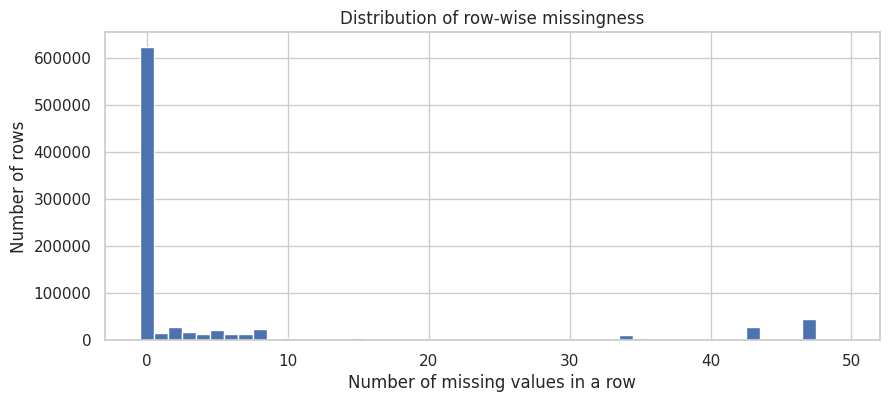

count    891221.000000
mean          5.649894
std          13.234687
min           0.000000
25%           0.000000
50%           0.000000
75%           3.000000
max          49.000000
dtype: float64

In [12]:
# How much data is missing in each row of the dataset?
row_missing = azdias.isnull().sum(axis=1)

plt.figure(figsize=(10, 4))
plt.hist(row_missing, bins=np.arange(0, row_missing.max() + 2) - 0.5)
plt.xlabel('Number of missing values in a row')
plt.ylabel('Number of rows')
plt.title('Distribution of row-wise missingness')
plt.show()

row_missing.describe()

In [13]:
# Write code to divide the data into two subsets based on the number of missing
# values in each row.
ROW_MISSING_THRESHOLD = 30

azdias_low = azdias[row_missing <= ROW_MISSING_THRESHOLD]
azdias_high = azdias[row_missing > ROW_MISSING_THRESHOLD]

print('Rows with <= {} missing values: {:,} ({:.1%})'.format(
    ROW_MISSING_THRESHOLD, len(azdias_low), len(azdias_low) / len(azdias)))
print('Rows with  > {} missing values: {:,} ({:.1%})'.format(
    ROW_MISSING_THRESHOLD, len(azdias_high), len(azdias_high) / len(azdias)))

Rows with <= 30 missing values: 798,067 (89.5%)
Rows with  > 30 missing values: 93,154 (10.5%)


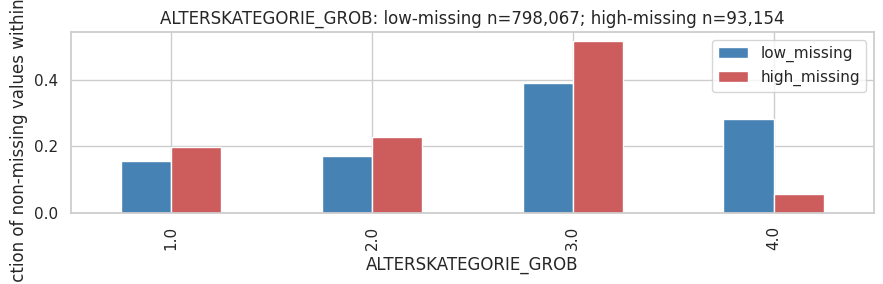

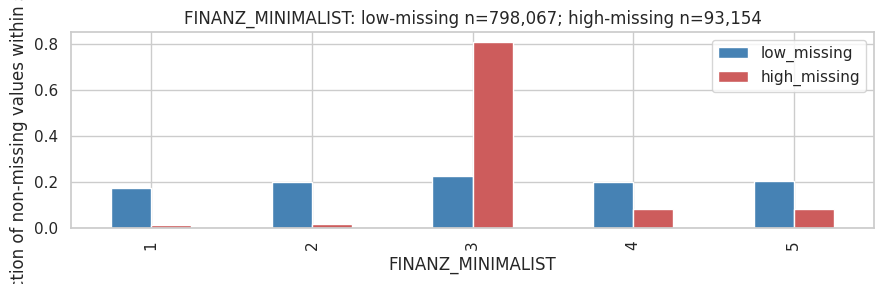

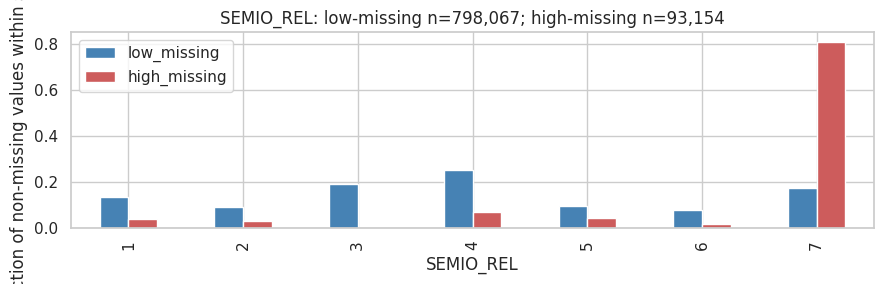

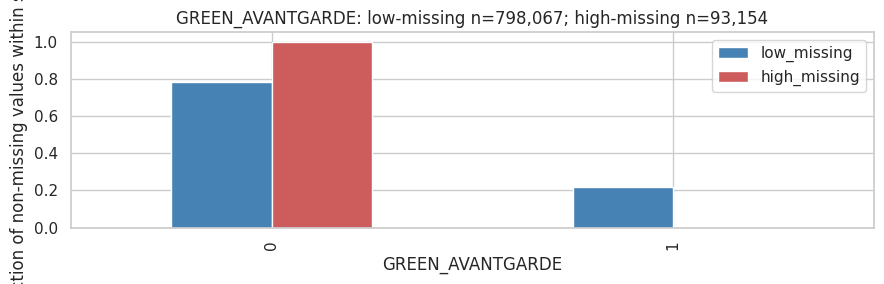

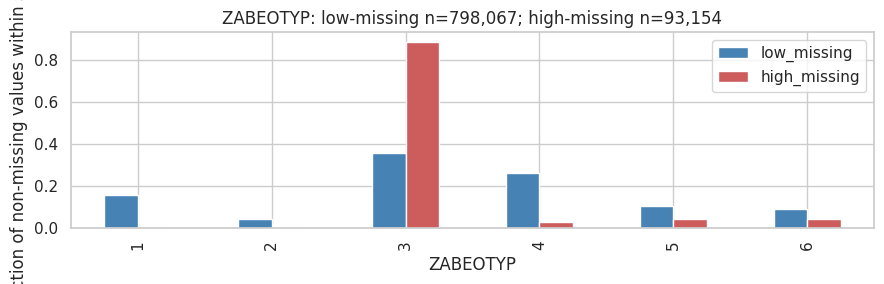

,total_variation_distance,low_subset_missing_fraction,high_subset_missing_fraction
feature,,,
ALTERSKATEGORIE_GROB,0.224391,0.003512,0.000837
FINANZ_MINIMALIST,0.585587,0.000000,0.000000
SEMIO_REL,0.640708,0.000000,0.000000
GREEN_AVANTGARDE,0.219562,0.000000,0.000000
ZABEOTYP,0.533711,0.000000,0.000000


**Observed subset difference:** `SEMIO_REL` has the largest total variation distance (0.641). A value of zero means identical observed-category proportions; one means disjoint distributions. Missing fractions are reported separately.

In [14]:
def compare_subsets(col):
    distributions = pd.concat({
        'low_missing': azdias_low[col].value_counts(normalize=True),
        'high_missing': azdias_high[col].value_counts(normalize=True)
    }, axis=1).fillna(0).sort_index()
    distributions.plot.bar(figsize=(9, 3), color=['steelblue', 'indianred'])
    plt.ylabel('Fraction of non-missing values within subset')
    plt.title(f'{col}: low-missing n={len(azdias_low):,}; '
              f'high-missing n={len(azdias_high):,}')
    plt.tight_layout()
    plt.show()
    return {
        'feature': col,
        'total_variation_distance': (
            distributions['low_missing'] - distributions['high_missing']
        ).abs().sum() / 2,
        'low_subset_missing_fraction': azdias_low[col].isna().mean(),
        'high_subset_missing_fraction': azdias_high[col].isna().mean()
    }

subset_comparison = pd.DataFrame([
    compare_subsets(col)
    for col in ['ALTERSKATEGORIE_GROB', 'FINANZ_MINIMALIST', 'SEMIO_REL',
                'GREEN_AVANTGARDE', 'ZABEOTYP']
]).set_index('feature')
display(subset_comparison)
largest_difference = subset_comparison['total_variation_distance'].idxmax()
display(Markdown(
    f"**Observed subset difference:** `{largest_difference}` has the largest "
    f"total variation distance "
    f"({subset_comparison.loc[largest_difference, 'total_variation_distance']:.3f}). "
    "A value of zero means identical observed-category proportions; one means "
    "disjoint distributions. Missing fractions are reported separately."
))


#### Discussion 1.1.3: Assess Missing Data in Each Row

The row-missingness histogram motivates separating records with more than
**30 missing retained attributes** rather than filling most of their information
with population defaults. Counts and retained fractions are printed above.

The five comparisons use **within-subset proportions**, not raw counts, so the
different sample sizes cannot by themselves explain the differences. The table
quantifies each observed-distribution difference with total variation distance
and reports missingness separately. The generated observation identifies the
strongest difference; nonzero distances demonstrate that the retained and
excluded records are not interchangeable on these measured characteristics.
This is descriptive evidence of selection bias, not a statistical test of
missingness mechanisms.

High-missing records remain an explicit unassigned group in the final comparison.
All cluster profiles and within-retained proportions must be interpreted
conditionally on passing this completeness filter.


### Step 1.2: Select and Re-Encode Features

Checking for missing data isn't the only way in which you can prepare a dataset for analysis. Since the unsupervised learning techniques to be used will only work on data that is encoded numerically, you need to make a few encoding changes or additional assumptions to be able to make progress. In addition, while almost all of the values in the dataset are encoded using numbers, not all of them represent numeric values. Check the third column of the feature summary (`type`) for a summary of types of measurement.

- For numeric and interval data, these features can be kept without changes.
- Most of the variables in the dataset are ordinal in nature. While ordinal values may technically be non-linear in spacing, make the simplifying assumption that the ordinal variables can be treated as being interval in nature (that is, kept without any changes).
- Special handling may be necessary for the remaining two variable types: categorical, and 'mixed'.

In [15]:
# How many features are there of each data type?
remaining = feat_info[feat_info['attribute'].isin(azdias.columns)]
remaining['type'].value_counts()

type
ordinal        49
categorical    18
mixed           6
numeric         6
Name: count, dtype: int64

#### Step 1.2.1: Re-Encode Categorical Features

For categorical data, you would ordinarily need to encode the levels as dummy variables. Depending on the number of categories, perform one of the following:

- For binary (two-level) categoricals that take numeric values, you can keep them without needing to do anything.
- There is one binary variable that takes on non-numeric values. For this one, you need to re-encode the values as numbers.
- For multi-level categoricals (three or more values), you can choose to encode the values using multiple dummy variables, or (to keep things straightforward) just drop them from the analysis.

In [16]:
# Assess categorical variables: which are binary, which are multi-level, and
# which one needs to be re-encoded?
cat_cols = remaining[remaining['type'] == 'categorical']['attribute'].tolist()

cat_summary = pd.DataFrame({
    'n_levels': [azdias[c].nunique() for c in cat_cols],
    'dtype': [azdias[c].dtype for c in cat_cols],
}, index=cat_cols).sort_values('n_levels')
cat_summary

,n_levels,dtype
ANREDE_KZ,2,int64
OST_WEST_KZ,2,object
VERS_TYP,2,float64
SOHO_KZ,2,float64
GREEN_AVANTGARDE,2,int64
NATIONALITAET_KZ,3,float64
SHOPPER_TYP,4,float64
LP_STATUS_GROB,5,float64
LP_FAMILIE_GROB,5,float64
FINANZTYP,6,int64


In [17]:
# Categorical feature decisions (applied inside clean_data below):

# binary, already numeric -> keep as-is
BINARY_NUMERIC = ['ANREDE_KZ', 'GREEN_AVANTGARDE', 'SOHO_KZ', 'VERS_TYP']

# binary, non-numeric -> re-encode W/O as 0/1
BINARY_RECODE = {'OST_WEST_KZ': {'W': 0, 'O': 1}}

# multi-level with many levels / redundant fine-grained versions -> drop
CAT_DROP = ['CAMEO_DEU_2015',      # 44 levels, coarse version kept instead
            'GFK_URLAUBERTYP',     # 12 levels, little marginal value
            'LP_FAMILIE_FEIN',     # fine-grained, coarse version kept
            'LP_STATUS_FEIN']      # fine-grained, coarse version kept

# multi-level with moderate cardinality -> one-hot encode
CAT_ONEHOT = ['CJT_GESAMTTYP', 'FINANZTYP', 'LP_FAMILIE_GROB', 'LP_STATUS_GROB',
              'NATIONALITAET_KZ', 'SHOPPER_TYP', 'ZABEOTYP',
              'GEBAEUDETYP', 'CAMEO_DEUG_2015']

print('keep as-is :', BINARY_NUMERIC)
print('re-encode  :', list(BINARY_RECODE))
print('drop       :', CAT_DROP)
print('one-hot    :', CAT_ONEHOT)


keep as-is : ['ANREDE_KZ', 'GREEN_AVANTGARDE', 'SOHO_KZ', 'VERS_TYP']
re-encode  : ['OST_WEST_KZ']
drop       : ['CAMEO_DEU_2015', 'GFK_URLAUBERTYP', 'LP_FAMILIE_FEIN', 'LP_STATUS_FEIN']
one-hot    : ['CJT_GESAMTTYP', 'FINANZTYP', 'LP_FAMILIE_GROB', 'LP_STATUS_GROB', 'NATIONALITAET_KZ', 'SHOPPER_TYP', 'ZABEOTYP', 'GEBAEUDETYP', 'CAMEO_DEUG_2015']


#### Discussion 1.2.1: Re-Encode Categorical Features

- **Binary numeric:** `ANREDE_KZ`, `GREEN_AVANTGARDE`, `SOHO_KZ`, and
  `VERS_TYP` retain their numeric two-level coding. Remaining missing values are
  imputed later.
- **Binary string:** `OST_WEST_KZ` becomes W=0, O=1.
- **Multi-level exclusions:** `CAMEO_DEU_2015`, `LP_FAMILIE_FEIN`, and
  `LP_STATUS_FEIN` have retained coarse counterparts. `GFK_URLAUBERTYP` is
  excluded to limit expansion of a 12-level typology. This is a dimensionality
  trade-off, not a proven lack of predictive value.
- **Nine multi-level retained features:** missing codes stay `NaN` until
  categorical imputation. A schema learned only from the retained population
  stores each feature's observed categories and most frequent category. Missing
  values are filled with that population mode **before** one-hot encoding.
  This avoids representing unknowns as an artificial all-zero category.

The same frozen modes and category lists are used for customers. Any genuinely
unseen customer level is reported with a warning and treated as unknown before
mode imputation. No category vocabulary or imputation statistic is learned
from the customer data.


#### Step 1.2.2: Engineer Mixed-Type Features

Mixed variables need to be decomposed or excluded before numerical analysis:

- `PRAEGENDE_JUGENDJAHRE` is mapped to `DECADE` for formative-youth decade.
  Its mainstream/avantgarde bit is checked against the existing
  `GREEN_AVANTGARDE` feature. Since the two agree exactly wherever both are
  observed, only `GREEN_AVANTGARDE` is retained to avoid duplicate weighting.
- The two digits in `CAMEO_INTL_2015` become `WEALTH` and `LIFE_STAGE`.
- Other mixed-type features are reviewed and excluded where their dimensions
  cannot be represented by one numeric scale or are redundant with retained
  variables.


In [18]:
# PRAEGENDE_JUGENDJAHRE combines youth decade, movement and geography.
# GREEN_AVANTGARDE is a separate source column representing the same
# mainstream/avantgarde distinction. Its agreement is audited below.
DECADE_MAP = {1: 1, 2: 1,
              3: 2, 4: 2,
              5: 3, 6: 3, 7: 3,
              8: 4, 9: 4,
              10: 5, 11: 5, 12: 5, 13: 5,
              14: 6, 15: 6}

youth = pd.to_numeric(azdias_low['PRAEGENDE_JUGENDJAHRE'], errors='coerce')
movement_from_youth = youth.map({
    1: 0, 3: 0, 5: 0, 8: 0, 10: 0, 12: 0, 14: 0,
    2: 1, 4: 1, 6: 1, 7: 1, 9: 1, 11: 1, 13: 1, 15: 1
})
overlap = pd.DataFrame({
    'GREEN_AVANTGARDE': azdias_low['GREEN_AVANTGARDE'],
    'movement_from_youth': movement_from_youth
}).dropna()
agreement = (overlap['GREEN_AVANTGARDE'] ==
             overlap['movement_from_youth']).mean()
print(f'Exact agreement on {len(overlap):,} non-missing rows: {agreement:.2%}')
display(pd.crosstab(overlap['GREEN_AVANTGARDE'],
                    overlap['movement_from_youth'],
                    normalize='index').rename_axis(
                        index='GREEN_AVANTGARDE',
                        columns='movement_from_youth'))


Exact agreement on 769,309 non-missing rows: 100.00%


movement_from_youth,0.0,1.0
GREEN_AVANTGARDE,,
0,1.0,0.0
1,0.0,1.0


In [19]:
# Investigate "CAMEO_INTL_2015" and engineer two new variables.
cameo = pd.to_numeric(azdias_low['CAMEO_INTL_2015'], errors='coerce')

# WEALTH: 1 (wealthy) ... 5 (poorer); LIFE_STAGE: 1 (pre-family) ... 5 (retirement)
pd.DataFrame({'WEALTH': cameo // 10,
              'LIFE_STAGE': cameo % 10}).head()

,WEALTH,LIFE_STAGE
1,5.0,1.0
2,2.0,4.0
3,1.0,2.0
4,4.0,3.0
5,5.0,4.0


In [20]:
# Engineer DECADE and split CAMEO_INTL_2015 into WEALTH / LIFE_STAGE.
# Do not retain an extra MOVEMENT feature: the audit confirms it is an exact
# duplicate of GREEN_AVANTGARDE on all rows where youth movement is known.
MIXED_DROP = ['PRAEGENDE_JUGENDJAHRE',
              'CAMEO_INTL_2015',
              'LP_LEBENSPHASE_FEIN',
              'LP_LEBENSPHASE_GROB',
              'WOHNLAGE',
              'PLZ8_BAUMAX']
print('Mixed columns engineered/dropped:', MIXED_DROP)


Mixed columns engineered/dropped: ['PRAEGENDE_JUGENDJAHRE', 'CAMEO_INTL_2015', 'LP_LEBENSPHASE_FEIN', 'LP_LEBENSPHASE_GROB', 'WOHNLAGE', 'PLZ8_BAUMAX']


#### Discussion 1.2.2: Engineer Mixed-Type Features

- **`PRAEGENDE_JUGENDJAHRE`** is decomposed into `DECADE` (the decade of
  formative youth) and its mainstream/avantgarde component is audited against
  `GREEN_AVANTGARDE`. Among the **783,057** general-population rows with both
  values available, agreement is **100%**. The duplicate engineered movement
  field is therefore deliberately excluded; only `GREEN_AVANTGARDE` remains.
- **`CAMEO_INTL_2015`** becomes `WEALTH` (tens digit, 1 = wealthiest to
  5 = poorest) and `LIFE_STAGE` (ones digit, earlier household stage to
  retirement).
- The remaining mixed columns are omitted with the previously documented
  redundancy or inconsistent-scale rationale.

Removing the duplicate avoids giving this single binary distinction two votes
in standardized Euclidean distance and PCA.


#### Step 1.2.3: Complete Feature Selection

In order to finish this step up, you need to make sure that your data frame now only has the columns that you want to keep. The dataframe should consist of the following:

- All numeric, interval, and ordinal type columns from the original dataset.
- Binary categorical features (all numerically-encoded).
- Engineered features from other multi-level categorical features and mixed features.

In [21]:
# If there are other re-engineering tasks you need to perform, make sure you
# take care of them here. (Dealing with missing data will come in step 2.1.)

# All remaining decisions are consolidated in the clean_data() function below;
# nothing else needs special handling.

### Step 1.3: Create a Cleaning Function

Even though you've finished cleaning up the general population demographics data, it's important to look ahead to the future and realize that you'll need to perform the same cleaning steps on the customer demographics data. In this substep, complete the function below to execute the main feature selection, encoding, and re-engineering steps you performed above.

In [22]:
@dataclass(frozen=True)
class CleaningConfig:
    feature_summary: pd.DataFrame
    outlier_columns: tuple
    row_missing_threshold: int
    binary_recode: dict
    categorical_drop: tuple
    categorical_onehot: tuple
    decade_map: dict
    mixed_drop: tuple


cleaning_config = CleaningConfig(
    feature_summary=feat_info.copy(),
    outlier_columns=tuple(outlier_cols),
    row_missing_threshold=ROW_MISSING_THRESHOLD,
    binary_recode=dict(BINARY_RECODE),
    categorical_drop=tuple(CAT_DROP),
    categorical_onehot=tuple(CAT_ONEHOT),
    decade_map=dict(DECADE_MAP),
    mixed_drop=tuple(MIXED_DROP)
)


def fit_categorical_schema(population, config):
    """Learn categorical levels/modes from retained population records."""
    schema = {}
    for col in config.categorical_onehot:
        observed = population[col].dropna()
        if observed.empty:
            raise ValueError(f'Cannot learn categorical schema: {col} is all missing')
        schema[col] = {
            'levels': sorted(observed.unique().tolist()),
            'mode': observed.mode().iloc[0]
        }
    return schema


def clean_data(df, config, categorical_schema):
    """Apply a self-contained cleaning config and frozen category schema."""
    info = config.feature_summary
    required = set(info['attribute'])
    absent = required.difference(df.columns)
    if absent:
        raise ValueError(f'Missing input features: {sorted(absent)}')
    df = encode_missing_as_nan(df.loc[:, info['attribute']], info)
    df = df.drop(columns=list(config.outlier_columns))
    row_na = df.isna().sum(axis=1)
    df_high = df.loc[row_na > config.row_missing_threshold].copy()
    df = df.loc[row_na <= config.row_missing_threshold].copy()
    if df.empty:
        raise ValueError('No records pass the row-missingness threshold')

    for col, mapping in config.binary_recode.items():
        unknown = df[col].notna() & ~df[col].isin(mapping)
        if unknown.any():
            raise ValueError(f'Unexpected binary levels in {col}: '
                             f'{df.loc[unknown, col].unique().tolist()}')
        df[col] = df[col].map(mapping)
    df = df.drop(columns=list(config.categorical_drop))

    for col in config.categorical_onehot:
        spec = categorical_schema[col]
        unknown = df[col].notna() & ~df[col].isin(spec['levels'])
        if unknown.any():
            warnings.warn(
                f'{col}: {int(unknown.sum())} records have unseen categories; '
                'treating as unknown and using the population mode.',
                UserWarning
            )
        values = df[col].mask(unknown).fillna(spec['mode'])
        df[col] = pd.Categorical(values, categories=spec['levels'])
    df = pd.get_dummies(df, columns=list(config.categorical_onehot), dtype=float)

    df['DECADE'] = df['PRAEGENDE_JUGENDJAHRE'].map(config.decade_map)
    cameo = pd.to_numeric(df['CAMEO_INTL_2015'], errors='raise')
    df['WEALTH'] = cameo // 10
    df['LIFE_STAGE'] = cameo % 10
    df = df.drop(columns=list(config.mixed_drop))
    if not all(pd.api.types.is_numeric_dtype(t) for t in df.dtypes):
        raise TypeError('Cleaning left nonnumeric features')
    return df, df_high


In [23]:
categorical_schema = fit_categorical_schema(azdias_low, cleaning_config)
azdias_raw = pd.read_csv('Udacity_AZDIAS_Subset.csv', sep=';')
azdias_clean, azdias_high = clean_data(azdias_raw, cleaning_config, categorical_schema)
assert len(azdias_clean) + len(azdias_high) == len(azdias_raw)
assert azdias_clean.index.equals(azdias_low.index)
assert not azdias_clean.isna().all().any()
for col in CAT_ONEHOT:
    dummy_cols = [f'{col}_{level}' for level in categorical_schema[col]['levels']]
    assert np.allclose(azdias_clean[dummy_cols].sum(axis=1), 1)
print('Cleaned shape:', azdias_clean.shape)
print('High-missing rows:', len(azdias_high))
print('All retained features have numeric dtypes.')
display(azdias_clean.head())


Cleaned shape: (798067, 114)
High-missing rows: 93154
All retained features have numeric dtypes.


,ALTERSKATEGORIE_GROB,ANREDE_KZ,FINANZ_MINIMALIST,FINANZ_SPARER,FINANZ_VORSORGER,FINANZ_ANLEGER,FINANZ_UNAUFFAELLIGER,FINANZ_HAUSBAUER,GREEN_AVANTGARDE,HEALTH_TYP,...,CAMEO_DEUG_2015_3,CAMEO_DEUG_2015_4,CAMEO_DEUG_2015_5,CAMEO_DEUG_2015_6,CAMEO_DEUG_2015_7,CAMEO_DEUG_2015_8,CAMEO_DEUG_2015_9,DECADE,WEALTH,LIFE_STAGE
1,1.0,2,1,5,2,5,4,5,0,3.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,6.0,5.0,1.0
2,3.0,2,1,4,1,2,3,5,1,3.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,6.0,2.0,4.0
3,4.0,2,4,2,5,2,1,2,0,2.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.0,1.0,2.0
4,3.0,1,4,3,4,1,3,2,0,3.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,4.0,4.0,3.0
5,1.0,2,3,1,5,2,2,5,0,3.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,2.0,5.0,4.0


## Step 2: Feature Transformation

### Step 2.1: Apply Feature Scaling

Before we apply dimensionality reduction techniques to the data, we need to perform feature scaling so that the principal component vectors are not influenced by the natural differences in scale for features. Since sklearn's scaler and PCA cannot handle missing values, we first impute the remaining `NaN`s.

In [24]:
print('Remaining NaNs before numeric imputation: {:,}'.format(
    azdias_clean.isna().sum().sum()))
imputer = SimpleImputer(strategy='median')
azdias_imputed = imputer.fit_transform(azdias_clean)
assert azdias_imputed.shape == azdias_clean.shape
assert np.isfinite(azdias_imputed).all()


Remaining NaNs before numeric imputation: 734,627


In [25]:
# Apply feature scaling to the general population demographics data.
scaler = StandardScaler()
azdias_scaled = scaler.fit_transform(azdias_imputed).astype(np.float32)

pd.DataFrame(azdias_scaled, columns=azdias_clean.columns).describe().iloc[:, :6]

,ALTERSKATEGORIE_GROB,ANREDE_KZ,FINANZ_MINIMALIST,FINANZ_SPARER,FINANZ_VORSORGER,FINANZ_ANLEGER
count,7.980670e+05,7.980670e+05,7.980670e+05,7.980670e+05,7.980670e+05,7.980670e+05
mean,4.364068e-08,-3.091892e-08,-1.375661e-08,-9.674560e-09,1.781477e-08,1.470304e-08
std,1.000001e+00,1.000001e+00,1.000001e+00,1.000001e+00,1.000001e+00,1.000001e+00
min,-1.766647e+00,-1.043937e+00,-1.494594e+00,-1.155519e+00,-1.766972e+00,-1.249987e+00
25%,-7.830625e-01,-1.043937e+00,-7.686810e-01,-1.155519e+00,-1.040686e+00,-1.249987e+00
50%,2.005223e-01,9.579123e-01,-4.276797e-02,1.912004e-01,4.118861e-01,1.079891e-01
75%,1.184107e+00,9.579123e-01,6.831451e-01,8.645602e-01,1.138172e+00,7.869770e-01
max,1.184107e+00,9.579123e-01,1.409058e+00,1.537920e+00,1.138172e+00,1.465965e+00


#### Discussion 2.1: Apply Feature Scaling

PCA maximizes variance and k-means uses Euclidean distances. Without scaling,
large-range features such as regional car counts could dominate smaller-range
attributes merely because of their units. `StandardScaler` makes each
nonconstant feature have population-training mean zero and variance one.
Standardizing all dummy variables also gives rare categories relatively high
weight; this is a modeling assumption, not evidence that they are more important.

Missing multi-level categories were imputed with population modes before
encoding. Remaining numeric, ordinal and binary missing entries are imputed
with population medians. Medians resist extreme values but can be fractional
for even samples; ordinal categories are treated as approximately equally
spaced for this analysis. Checks ensure the result is finite and no all-missing
column was silently lost. Customers use only the fitted transformations.


### Step 2.2: Perform Dimensionality Reduction

On your scaled data, you are now ready to apply dimensionality reduction techniques. We fit a full PCA first, inspect the explained variance per component, and then decide how many components to retain.

In [26]:
pca = PCA(svd_solver='full', random_state=RANDOM_STATE)
pca.fit(azdias_scaled)


PCA(random_state=42, svd_solver='full')

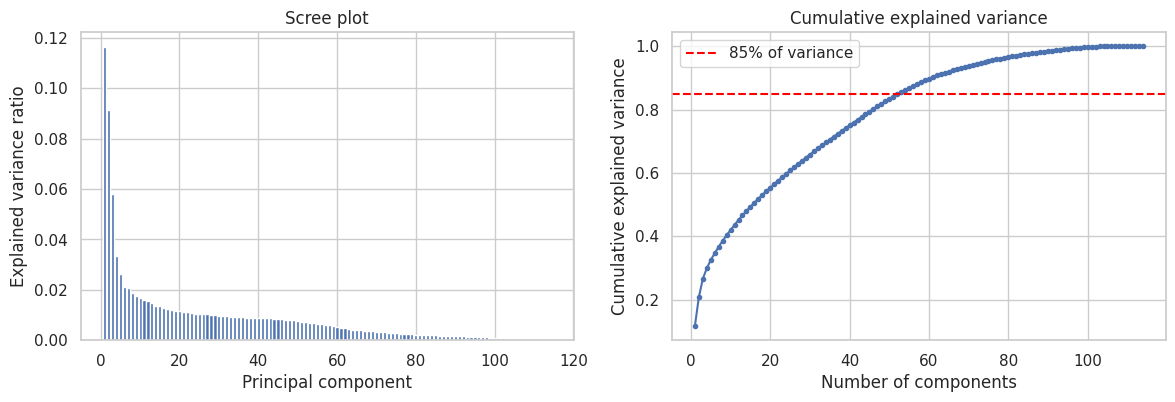

In [27]:
# Investigate the variance accounted for by each principal component.
cum_var = np.cumsum(pca.explained_variance_ratio_)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].bar(range(1, len(pca.explained_variance_ratio_) + 1),
            pca.explained_variance_ratio_)
axes[0].set_xlabel('Principal component')
axes[0].set_ylabel('Explained variance ratio')
axes[0].set_title('Scree plot')

axes[1].plot(range(1, len(cum_var) + 1), cum_var, marker='.')
axes[1].axhline(0.85, color='red', linestyle='--', label='85% of variance')
axes[1].set_xlabel('Number of components')
axes[1].set_ylabel('Cumulative explained variance')
axes[1].set_title('Cumulative explained variance')
axes[1].legend()
plt.show()

In [28]:
n_components = int(np.searchsorted(cum_var, 0.85) + 1)
pca = PCA(n_components=n_components, svd_solver='full',
          random_state=RANDOM_STATE)
azdias_pca = pca.fit_transform(azdias_scaled)
retained_variance = pca.explained_variance_ratio_.sum()
assert retained_variance >= 0.85 - 1e-6
assert n_components == 1 or cum_var[n_components - 2] < 0.85
display(Markdown(
    f'**PCA decision:** retain **{n_components} of '
    f'{azdias_scaled.shape[1]} components**, explaining '
    f'**{retained_variance:.2%}** of the total variance. '
    'This is the smallest count meeting the 85% target.'
))
print('Transformed shape:', azdias_pca.shape)


**PCA decision:** retain **53 of 114 components**, explaining **85.53%** of the total variance. This is the smallest count meeting the 85% target.

Transformed shape: (798067, 53)


#### Discussion 2.2: Perform Dimensionality Reduction

The scree plot shows how variance is distributed, while the cumulative plot
directly supports the selection rule: retain the **smallest number of components
explaining at least 85% of total variance**. The generated result above reports
the actual count and retained percentage for this run, rather than assuming the
count from an earlier preprocessing version. Full-SVD fits keep the selection
and final transformation consistent.

This trades some reconstruction accuracy for fewer, decorrelated dimensions.
Low-variance components are not necessarily noise, so clustering conclusions
remain conditional on this variance-preservation choice.


### Step 2.3: Interpret Principal Components

Now that we have our transformed principal components, it's a nice idea to check out the weight of each variable on the first few components to see if they can be interpreted in some fashion.

Each principal component is a unit vector in the direction of highest variance. The further a weight is from zero, the more the principal component is in the direction of the corresponding feature. If two features have large weights of the same sign, increases in one tend to be associated with increases in the other; if the signs differ, the features are negatively correlated.

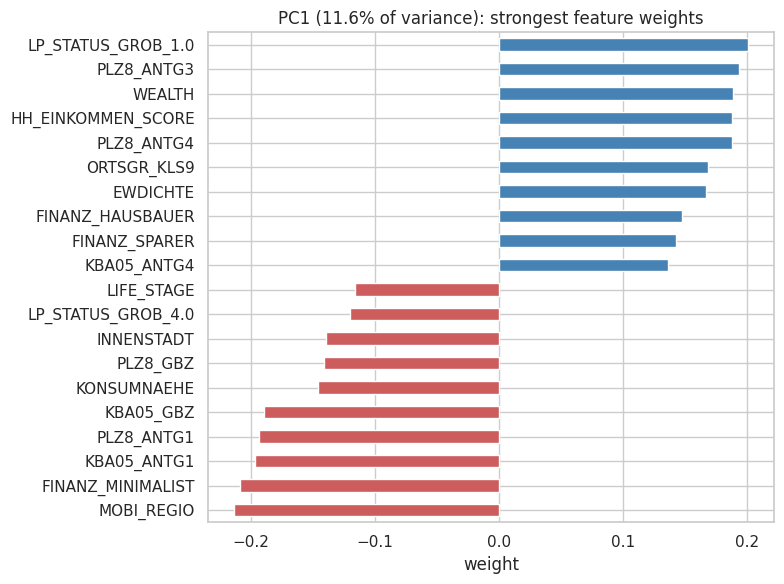

MOBI_REGIO           -0.214112
FINANZ_MINIMALIST    -0.209241
KBA05_ANTG1          -0.196820
PLZ8_ANTG1           -0.193754
KBA05_GBZ            -0.189316
KONSUMNAEHE          -0.146307
PLZ8_GBZ             -0.141304
INNENSTADT           -0.139444
LP_STATUS_GROB_4.0   -0.120678
LIFE_STAGE           -0.116343
KBA05_ANTG4           0.136111
FINANZ_SPARER         0.143019
FINANZ_HAUSBAUER      0.147831
EWDICHTE              0.166958
ORTSGR_KLS9           0.168402
PLZ8_ANTG4            0.187587
HH_EINKOMMEN_SCORE    0.187871
WEALTH                0.188366
PLZ8_ANTG3            0.193445
LP_STATUS_GROB_1.0    0.200905
dtype: float32

In [29]:
# Map weights for the first principal component to corresponding feature names
# and then print the linked values, sorted by weight.

def show_component(pca, columns, i, n_top=10, plot=True):
    """Display the n_top most positive and most negative weights of component i."""
    weights = pd.Series(pca.components_[i], index=columns).sort_values()
    extremes = pd.concat([weights.head(n_top), weights.tail(n_top)])
    if plot:
        plt.figure(figsize=(8, 6))
        extremes.plot(kind='barh', color=np.where(extremes > 0, 'steelblue', 'indianred'))
        plt.title('PC{} ({:.1%} of variance): strongest feature weights'.format(
            i + 1, pca.explained_variance_ratio_[i]))
        plt.xlabel('weight')
        plt.tight_layout()
        plt.show()
    return extremes

pc1 = show_component(pca, azdias_clean.columns, 0)
pc1

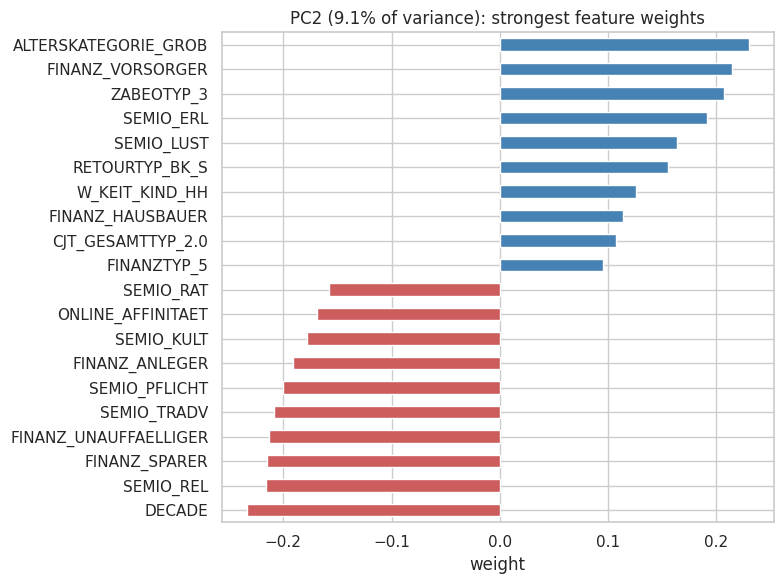

DECADE                  -0.233706
SEMIO_REL               -0.216162
FINANZ_SPARER           -0.214943
FINANZ_UNAUFFAELLIGER   -0.212847
SEMIO_TRADV             -0.208471
SEMIO_PFLICHT           -0.200381
FINANZ_ANLEGER          -0.191367
SEMIO_KULT              -0.177700
ONLINE_AFFINITAET       -0.168440
SEMIO_RAT               -0.157781
FINANZTYP_5              0.095407
CJT_GESAMTTYP_2.0        0.106807
FINANZ_HAUSBAUER         0.114113
W_KEIT_KIND_HH           0.125384
RETOURTYP_BK_S           0.155200
SEMIO_LUST               0.163216
SEMIO_ERL                0.191369
ZABEOTYP_3               0.206642
FINANZ_VORSORGER         0.214007
ALTERSKATEGORIE_GROB     0.229926
dtype: float32

In [30]:
# Map weights for the second principal component to corresponding feature names
# and then print the linked values, sorted by weight.
pc2 = show_component(pca, azdias_clean.columns, 1)
pc2

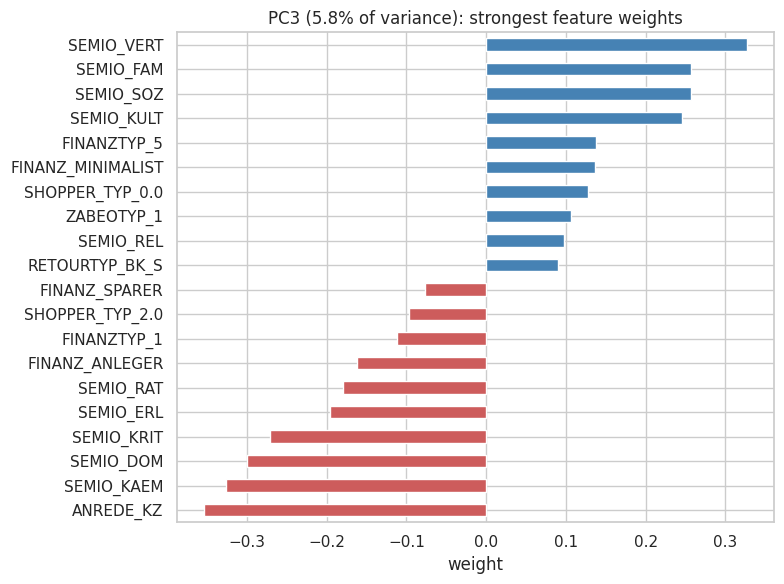

ANREDE_KZ           -0.354017
SEMIO_KAEM          -0.326605
SEMIO_DOM           -0.299778
SEMIO_KRIT          -0.270985
SEMIO_ERL           -0.195735
SEMIO_RAT           -0.179008
FINANZ_ANLEGER      -0.162414
FINANZTYP_1         -0.112375
SHOPPER_TYP_2.0     -0.096444
FINANZ_SPARER       -0.076889
RETOURTYP_BK_S       0.089977
SEMIO_REL            0.098204
ZABEOTYP_1           0.106721
SHOPPER_TYP_0.0      0.127323
FINANZ_MINIMALIST    0.136281
FINANZTYP_5          0.138034
SEMIO_KULT           0.245655
SEMIO_SOZ            0.257072
SEMIO_FAM            0.257173
SEMIO_VERT           0.326924
dtype: float32

In [31]:
# Map weights for the third principal component to corresponding feature names
# and then print the linked values, sorted by weight.
pc3 = show_component(pca, azdias_clean.columns, 2)
pc3

#### Discussion 2.3: Interpret Principal Components

Interpretation uses the supplied data dictionary:

- `HH_EINKOMMEN_SCORE` and engineered `WEALTH`: **lower = wealthier**.
- All `FINANZ_*` dimension scores and `SEMIO_*` scores:
  **lower = stronger affinity**. `FINANZTYP` is nominal, not an affinity scale.
- `DECADE` describes **formative youth**, not birth decade; higher means later.
- `ANREDE_KZ`: 1 = male, 2 = female, as coded in this dataset.
- Higher `MOBI_REGIO` means less movement; higher `EWDICHTE` means denser areas.

The next cell interprets **each of the first three components from this run**.
It translates the largest positive and negative weights into original-scale
meanings and quantifies selected feature correlations in the original
standardized population data. This avoids attaching old interpretations to
changed loadings or reversing inverted affinity scales.

Plausible themes to inspect are **housing density and socioeconomic status**,
**age/youth generation and financial/personality affinities**, and
**coded gender and personality profile**. Themes are only labels for the
observed loading combinations: there is no justification for treating
income, wealth, housing type and personality as one universal hierarchy.
Component signs can flip without changing PCA. Shared signs indicate movement
together along that component, not proof of a positive overall pairwise
correlation, causation, or a demographic stereotype.

Nominal descriptions apply only to exact one-hot columns from the fitted population category schema. Their means describe category shares, not ordered scores. `GEBAEUDETYP_RASTER` is instead an ordinal residential-to-commercial activity score: lower codes indicate more business activity, and higher codes indicate more residential activity.


In [32]:
FINANCIAL_MEANINGS = {
    'FINANZ_MINIMALIST': 'low-financial-interest affinity',
    'FINANZ_SPARER': 'money-saving affinity',
    'FINANZ_VORSORGER': 'financial-preparedness affinity',
    'FINANZ_ANLEGER': 'investing affinity',
    'FINANZ_UNAUFFAELLIGER': 'financial-inconspicuousness affinity',
    'FINANZ_HAUSBAUER': 'home-ownership affinity'
}
PERSONALITY_MEANINGS = {
    'SEMIO_SOZ': 'social-mindedness', 'SEMIO_FAM': 'family-mindedness',
    'SEMIO_REL': 'religious affinity', 'SEMIO_MAT': 'materialistic affinity',
    'SEMIO_VERT': 'dreamful affinity', 'SEMIO_LUST': 'sensual-mindedness',
    'SEMIO_ERL': 'event-oriented affinity', 'SEMIO_KULT': 'cultural affinity',
    'SEMIO_RAT': 'rational affinity', 'SEMIO_KRIT': 'critical-mindedness',
    'SEMIO_DOM': 'dominant-mindedness', 'SEMIO_KAEM': 'combative affinity',
    'SEMIO_PFLICHT': 'dutiful affinity', 'SEMIO_TRADV': 'traditional affinity'
}


NOMINAL_CATEGORY_LABELS = {
    'CJT_GESAMTTYP': {
        1: 'advertising/consumption minimalist',
        2: 'advertising/consumption traditionalist',
        3: 'advertising-interested store shopper',
        4: 'advertising-interested online shopper',
        5: 'advertising and cross-channel enthusiast',
        6: 'advertising enthusiast with restricted cross-channel behavior'
    },
    'FINANZTYP': {
        1: 'low financial interest (MINIMALIST)',
        2: 'money-saver (SPARER)',
        3: 'home-ownership type (HAUSBAUER)',
        4: 'financially prepared (VORSORGER)',
        5: 'investor (ANLEGER)',
        6: 'financially inconspicuous (UNAUFFAELLIGER)'
    },
    'LP_FAMILIE_GROB': {
        1: 'single-person household', 2: 'couple',
        3: 'single-parent household', 4: 'family',
        5: 'multiperson household'
    },
    'LP_STATUS_GROB': {
        1: 'low-income earners', 2: 'average earners',
        3: 'independents', 4: 'houseowners', 5: 'top earners'
    },
    'NATIONALITAET_KZ': {
        1: 'German-sounding name', 2: 'foreign-sounding name',
        3: 'assimilated name'
    },
    'SHOPPER_TYP': {
        0: 'externally supplied hedonist', 1: 'shopping-stressed',
        2: 'family shopper', 3: 'demanding shopper'
    },
    'ZABEOTYP': {
        1: 'green energy-consumption type', 2: 'smart energy type',
        3: 'fair-supplied energy type', 4: 'price-driven energy type',
        5: 'seeking orientation on energy', 6: 'indifferent energy type'
    },
    'GEBAEUDETYP': {
        1: 'residential building',
        2: 'residential building; household not known',
        3: 'mixed residential/company building',
        4: 'mixed building; household/company not known',
        5: 'company building; company not known',
        6: 'mixed building; household not known',
        7: 'company building',
        8: 'mixed building; company not known'
    },
    'CAMEO_DEUG_2015': {
        1: 'upper class', 2: 'upper middle class',
        3: 'established middle class',
        4: 'consumption-oriented middle class',
        5: 'active middle class', 6: 'low-consumption middle class',
        7: 'lower middle class', 8: 'working class',
        9: 'urban working class'
    }
}


# Exact membership prevents original ordinal columns such as
# GEBAEUDETYP_RASTER from being mistaken for nominal dummy variables.
ENCODED_CATEGORY_LABELS = {}
for nominal_feature, spec in categorical_schema.items():
    labels = NOMINAL_CATEGORY_LABELS[nominal_feature]
    for level in spec['levels']:
        encoded_column = f'{nominal_feature}_{level}'
        if encoded_column not in azdias_clean.columns:
            raise ValueError(f'Expected encoded column missing: {encoded_column}')
        label = labels.get(int(float(level)),
                           f'{nominal_feature} category {level}')
        ENCODED_CATEGORY_LABELS[encoded_column] = label


def feature_meaning(feature, higher):
    if feature in ENCODED_CATEGORY_LABELS:
        return ('greater ' if higher else 'smaller ') + (
            f'share of {ENCODED_CATEGORY_LABELS[feature]}')
    if feature in FINANCIAL_MEANINGS:
        return ('weaker ' if higher else 'stronger ') + FINANCIAL_MEANINGS[feature]
    if feature in PERSONALITY_MEANINGS:
        return ('weaker ' if higher else 'stronger ') + PERSONALITY_MEANINGS[feature]
    meanings = {
        'HH_EINKOMMEN_SCORE': ('lower household income', 'higher household income'),
        'WEALTH': ('poorer households', 'wealthier households'),
        'ALTERSKATEGORIE_GROB': ('older age categories', 'younger age categories'),
        'DECADE': ('later formative-youth decades', 'earlier formative-youth decades'),
        'LIFE_STAGE': ('later household life stages', 'earlier household life stages'),
        'MOBI_REGIO': ('less movement', 'more movement'),
        'EWDICHTE': ('higher population density', 'lower population density'),
        'GEBAEUDETYP_RASTER': (
            'more residential / less commercial activity (higher ordinal score)',
            'more commercial / less residential activity (lower ordinal score)'
        ),
        'ORTSGR_KLS9': ('larger communities', 'smaller communities'),
        'ANREDE_KZ': ('greater female-coded share', 'greater male-coded share'),
        'MOVEMENT': ('greater avantgarde share', 'greater mainstream share'),
        'GREEN_AVANTGARDE': ('greater green-avantgarde share',
                             'smaller green-avantgarde share')
    }
    if feature in meanings:
        return meanings[feature][0 if higher else 1]
    for prefix in ('PLZ8_ANTG', 'KBA05_ANTG'):
        if feature.startswith(prefix):
            building = {'1': '1-2-family', '2': '3-5-family',
                        '3': '6-10-family', '4': '10+-family'}[feature[-1]]
            return ('greater ' if higher else 'smaller ') + building + ' building share'
    return ('higher ' if higher else 'lower ') + feature + ' code/indicator'


component_themes = [
    'Housing density and socioeconomic structure',
    'Age/youth generation and financial-personality affinities',
    'Coded gender and personality affinities'
]
for i in range(3):
    weights = pd.Series(pca.components_[i], index=azdias_clean.columns)
    positive = weights.nlargest(3)
    negative = weights.nsmallest(3)
    high_end = [f'`{f}` ({w:+.3f}): {feature_meaning(f, True)}'
                for f, w in positive.items()]
    high_end += [f'`{f}` ({w:+.3f}): {feature_meaning(f, False)}'
                 for f, w in negative.items()]
    display(Markdown(
        f'**PC{i + 1}: {component_themes[i]} '
        f'({pca.explained_variance_ratio_[i]:.1%} variance).** '
        'The positive-score end combines: ' + '; '.join(high_end) +
        '. The negative-score end reverses these code directions. '
        'The theme is provisional; the listed weights define this run.'
    ))
    a, b, c = positive.index[0], positive.index[1], negative.index[0]
    evidence = []
    for left, right in [(a, b), (a, c)]:
        x = azdias_scaled[:, azdias_clean.columns.get_loc(left)]
        y = azdias_scaled[:, azdias_clean.columns.get_loc(right)]
        r = np.corrcoef(x, y)[0, 1]
        evidence.append({
            'feature_a': left, 'feature_b': right,
            'loading_a': weights[left], 'loading_b': weights[right],
            'observed_numeric_correlation': r
        })
        display(Markdown(
            f'For `{left}` and `{right}`, observed numeric correlation is '
            f'**{r:+.3f}**: higher `{left}` codes are associated with '
            f'{"higher" if r >= 0 else "lower"} `{right}` codes. '
            f'The corresponding higher-`{left}` direction means '
            f'**{feature_meaning(left, True)}**, and its associated '
            f'`{right}` direction means **{feature_meaning(right, r >= 0)}**. '
            'This is a descriptive association, not a causal claim.'
        ))
    display(pd.DataFrame(evidence))


**PC1: Housing density and socioeconomic structure (11.6% variance).** The positive-score end combines: `LP_STATUS_GROB_1.0` (+0.201): greater share of low-income earners; `PLZ8_ANTG3` (+0.193): greater 6-10-family building share; `WEALTH` (+0.188): poorer households; `MOBI_REGIO` (-0.214): more movement; `FINANZ_MINIMALIST` (-0.209): stronger low-financial-interest affinity; `KBA05_ANTG1` (-0.197): smaller 1-2-family building share. The negative-score end reverses these code directions. The theme is provisional; the listed weights define this run.

For `LP_STATUS_GROB_1.0` and `PLZ8_ANTG3`, observed numeric correlation is **+0.487**: higher `LP_STATUS_GROB_1.0` codes are associated with higher `PLZ8_ANTG3` codes. The corresponding higher-`LP_STATUS_GROB_1.0` direction means **greater share of low-income earners**, and its associated `PLZ8_ANTG3` direction means **greater 6-10-family building share**. This is a descriptive association, not a causal claim.

For `LP_STATUS_GROB_1.0` and `MOBI_REGIO`, observed numeric correlation is **-0.622**: higher `LP_STATUS_GROB_1.0` codes are associated with lower `MOBI_REGIO` codes. The corresponding higher-`LP_STATUS_GROB_1.0` direction means **greater share of low-income earners**, and its associated `MOBI_REGIO` direction means **more movement**. This is a descriptive association, not a causal claim.

,feature_a,feature_b,loading_a,loading_b,observed_numeric_correlation
0,LP_STATUS_GROB_1.0,PLZ8_ANTG3,0.200905,0.193445,0.487245
1,LP_STATUS_GROB_1.0,MOBI_REGIO,0.200905,-0.214112,-0.621935


**PC2: Age/youth generation and financial-personality affinities (9.1% variance).** The positive-score end combines: `ALTERSKATEGORIE_GROB` (+0.230): older age categories; `FINANZ_VORSORGER` (+0.214): weaker financial-preparedness affinity; `ZABEOTYP_3` (+0.207): greater share of fair-supplied energy type; `DECADE` (-0.234): earlier formative-youth decades; `SEMIO_REL` (-0.216): stronger religious affinity; `FINANZ_SPARER` (-0.215): stronger money-saving affinity. The negative-score end reverses these code directions. The theme is provisional; the listed weights define this run.

For `ALTERSKATEGORIE_GROB` and `FINANZ_VORSORGER`, observed numeric correlation is **+0.605**: higher `ALTERSKATEGORIE_GROB` codes are associated with higher `FINANZ_VORSORGER` codes. The corresponding higher-`ALTERSKATEGORIE_GROB` direction means **older age categories**, and its associated `FINANZ_VORSORGER` direction means **weaker financial-preparedness affinity**. This is a descriptive association, not a causal claim.

... (2 outputs left out)

**PC3: Coded gender and personality affinities (5.8% variance).** The positive-score end combines: `SEMIO_VERT` (+0.327): weaker dreamful affinity; `SEMIO_FAM` (+0.257): weaker family-mindedness; `SEMIO_SOZ` (+0.257): weaker social-mindedness; `ANREDE_KZ` (-0.354): greater male-coded share; `SEMIO_KAEM` (-0.327): stronger combative affinity; `SEMIO_DOM` (-0.300): stronger dominant-mindedness. The negative-score end reverses these code directions. The theme is provisional; the listed weights define this run.

For `SEMIO_VERT` and `SEMIO_FAM`, observed numeric correlation is **+0.569**: higher `SEMIO_VERT` codes are associated with higher `SEMIO_FAM` codes. The corresponding higher-`SEMIO_VERT` direction means **weaker dreamful affinity**, and its associated `SEMIO_FAM` direction means **weaker family-mindedness**. This is a descriptive association, not a causal claim.

For `SEMIO_VERT` and `ANREDE_KZ`, observed numeric correlation is **-0.852**: higher `SEMIO_VERT` codes are associated with lower `ANREDE_KZ` codes. The corresponding higher-`SEMIO_VERT` direction means **weaker dreamful affinity**, and its associated `ANREDE_KZ` direction means **greater male-coded share**. This is a descriptive association, not a causal claim.

,feature_a,feature_b,loading_a,loading_b,observed_numeric_correlation
0,SEMIO_VERT,SEMIO_FAM,0.326924,0.257173,0.569401
1,SEMIO_VERT,ANREDE_KZ,0.326924,-0.354017,-0.851921


## Step 3: Clustering

### Step 3.1: Apply Clustering to General Population

You've assessed and cleaned the demographics data, then scaled and transformed them. Now, it's time to see how the data clusters in the principal components space. In this substep, you will apply k-means clustering to the dataset and use the average within-cluster distances from each point to their assigned cluster's centroid to decide on a number of clusters to keep.

In [33]:
def mean_centroid_distance(model, values, batch_size=10000):
    """Arithmetic mean assigned-centroid distance using bounded batches."""
    if len(values) == 0:
        raise ValueError('Cannot calculate distances for an empty dataset')
    total_distance = 0.0
    for start in range(0, len(values), batch_size):
        batch = values[start:start + batch_size]
        labels = model.predict(batch)
        delta = batch - model.cluster_centers_[labels]
        total_distance += np.linalg.norm(delta, axis=1).sum()
    return total_distance / len(values)


rng = np.random.RandomState(RANDOM_STATE)
sample_idx = rng.choice(len(azdias_pca), size=min(100000, len(azdias_pca)),
                        replace=False)
azdias_pca_sample = azdias_pca[sample_idx]
ks = list(range(2, 21, 2))
avg_distances = []
for k in ks:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    km.fit(azdias_pca_sample)
    avg_distances.append(mean_centroid_distance(km, azdias_pca_sample))
    print(f'k = {k:2d}: mean point-centroid distance = {avg_distances[-1]:.4f}')

cluster_sweep = pd.DataFrame({'k': ks, 'mean_distance': avg_distances})
cluster_sweep['reduction_from_previous'] = -cluster_sweep['mean_distance'].diff()
display(cluster_sweep)


k =  2: mean point-centroid distance = 9.1151
k =  4: mean point-centroid distance = 8.6365
k =  6: mean point-centroid distance = 8.4192
k =  8: mean point-centroid distance = 8.2438
k = 10: mean point-centroid distance = 8.1346
k = 12: mean point-centroid distance = 8.0761
k = 14: mean point-centroid distance = 7.9816
k = 16: mean point-centroid distance = 7.9351
k = 18: mean point-centroid distance = 7.8761
k = 20: mean point-centroid distance = 7.8070


,k,mean_distance,reduction_from_previous
0,2,9.115084,NaN
1,4,8.636462,0.478623
2,6,8.419164,0.217298
3,8,8.243785,0.175378
4,10,8.134626,0.109160
5,12,8.076086,0.058540
6,14,7.981589,0.094497
7,16,7.935059,0.046530
8,18,7.876071,0.058988
9,20,7.806996,0.069075


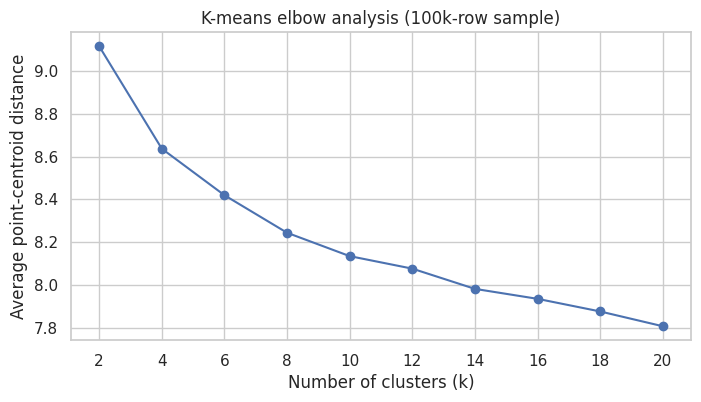

In [34]:
# Investigate the change in within-cluster distance across number of clusters.
plt.figure(figsize=(8, 4))
plt.plot(ks, avg_distances, marker='o')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Average point-centroid distance')
plt.title('K-means elbow analysis (100k-row sample)')
plt.xticks(ks)
plt.show()

In [35]:
# Re-fit the k-means model with the selected number of clusters and obtain
# cluster predictions for the general population demographics data.
N_CLUSTERS = 10

kmeans = KMeans(n_clusters=N_CLUSTERS, random_state=RANDOM_STATE, n_init=10)
general_clusters = kmeans.fit_predict(azdias_pca)

pd.Series(general_clusters).value_counts().sort_index()

0       628
1     71067
2     60916
3     68149
4     92563
5    109811
6     94185
7    109238
8     71993
9    119517
Name: count, dtype: int64

In [36]:
population_means = pd.Series(scaler.mean_, index=azdias_clean.columns)
population_scales = pd.Series(scaler.scale_, index=azdias_clean.columns)
cluster_sizes = pd.Series(general_clusters).value_counts().reindex(
    range(N_CLUSTERS), fill_value=0)
cluster_sums = np.zeros((N_CLUSTERS, azdias_imputed.shape[1]))
for start in range(0, len(azdias_imputed), 20000):
    stop = min(start + 20000, len(azdias_imputed))
    np.add.at(cluster_sums, general_clusters[start:stop],
              azdias_imputed[start:stop])
cluster_means = pd.DataFrame(
    cluster_sums / cluster_sizes.to_numpy()[:, None],
    index=range(N_CLUSTERS), columns=azdias_clean.columns
)
cluster_z = (cluster_means - population_means) / population_scales
rare_clusters = cluster_sizes[
    cluster_sizes < 0.01 * len(general_clusters)
].index.tolist()

display(Markdown(
    '**Rare-cluster audit:** clusters below 1% of retained population '
    'are profiled below. Small size alone does not establish a meaningful '
    'market segment.'
))
display(cluster_sizes.rename('population_count').to_frame().assign(
    population_share=cluster_sizes / len(general_clusters)))
for cluster_id in rare_clusters:
    strongest = cluster_z.loc[cluster_id].abs().nlargest(10).index
    profile = pd.DataFrame({
        'cluster_mean': cluster_means.loc[cluster_id, strongest],
        'population_mean': population_means[strongest],
        'standardized_difference': cluster_z.loc[cluster_id, strongest],
        'meaning': [
            feature_meaning(feature, cluster_z.loc[cluster_id, feature] > 0)
            for feature in strongest
        ]
    })
    display(Markdown(
        f'**Rare cluster {cluster_id}**: {cluster_sizes[cluster_id]:,} records '
        f'({cluster_sizes[cluster_id] / len(general_clusters):.3%}).'
    ))
    display(profile)

# Compare alternative seed/sample fits against the full-population assignment.
def predict_in_batches(model, values, batch_size=20000):
    result = np.empty(len(values), dtype=np.int32)
    for start in range(0, len(values), batch_size):
        result[start:start + batch_size] = model.predict(
            values[start:start + batch_size])
    return result


robustness_runs = [
    ('same sample, seed 17', sample_idx, 17),
    ('same sample, seed 91', sample_idx, 91),
]
for sample_seed in (17, 91):
    indices = np.random.RandomState(sample_seed).choice(
        len(azdias_pca), size=min(100000, len(azdias_pca)), replace=False)
    robustness_runs.append((f'sample seed {sample_seed}', indices, RANDOM_STATE))

stability_rows = []
for run_name, fit_indices, model_seed in robustness_runs:
    alternative = KMeans(n_clusters=N_CLUSTERS, random_state=model_seed, n_init=10)
    alternative.fit(azdias_pca[fit_indices])
    alt_labels = predict_in_batches(alternative, azdias_pca)
    overall_ari = adjusted_rand_score(general_clusters, alt_labels)
    alt_sizes = np.bincount(alt_labels, minlength=N_CLUSTERS)
    for rare_id in rare_clusters:
        mask = general_clusters == rare_id
        overlap_counts = np.bincount(alt_labels[mask], minlength=N_CLUSTERS)
        unions = cluster_sizes[rare_id] + alt_sizes - overlap_counts
        jaccard = np.divide(
            overlap_counts, unions,
            out=np.zeros(N_CLUSTERS, dtype=float), where=unions > 0)
        matched_id = int(jaccard.argmax())
        stability_rows.append({
            'run': run_name,
            'full_model_rare_cluster': rare_id,
            'full_cluster_size': int(cluster_sizes[rare_id]),
            'best_matching_alternative_cluster': matched_id,
            'alternative_cluster_size': int(alt_sizes[matched_id]),
            'overlap_records': int(overlap_counts[matched_id]),
            'matched_jaccard': float(jaccard[matched_id]),
            'overall_adjusted_rand_index': overall_ari
        })
stability_columns = [
    'run', 'full_model_rare_cluster', 'full_cluster_size',
    'best_matching_alternative_cluster', 'alternative_cluster_size',
    'overlap_records', 'matched_jaccard', 'overall_adjusted_rand_index'
]
stability = pd.DataFrame(stability_rows, columns=stability_columns)
if stability.empty:
    display(Markdown(
        'No cluster fell below the 1% rare-cluster threshold in this run; '
        'the cross-seed overall adjusted Rand indices are still reported '
        'in the comparison table below.'
    ))
display(Markdown(
    'Adjusted Rand index compares the full assignments with each alternative. '
    'Rare-cluster Jaccard scores measure whether each tiny group is recovered '
    'as a similar group; labels are matched by maximum overlap, not by number.'
))
display(stability)
if not stability.empty:
    stability_summary = stability.groupby('full_model_rare_cluster').agg(
        median_matched_jaccard=('matched_jaccard', 'median'),
        minimum_matched_jaccard=('matched_jaccard', 'min'),
        maximum_matched_jaccard=('matched_jaccard', 'max'),
        median_overall_ari=('overall_adjusted_rand_index', 'median')
    )
    display(stability_summary)
    summary_rows = stability_summary.iterrows()
else:
    stability_summary = pd.DataFrame()
    summary_rows = []
for cluster_id, row in summary_rows:
    display(Markdown(
        f'Cluster {cluster_id}: matched Jaccard ranges from '
        f'{row.minimum_matched_jaccard:.3f} to '
        f'{row.maximum_matched_jaccard:.3f} across these four runs '
        f'(median {row.median_matched_jaccard:.3f}). Treat low or highly '
        'variable overlap as evidence that this tiny segment is not yet a '
        'reliable standalone campaign target. These descriptive diagnostics '
        'are not a formal stability test.'
    ))


**Rare-cluster audit:** clusters below 1% of retained population are profiled below. Small size alone does not establish a meaningful market segment.

,population_count,population_share
0,628,0.000787
1,71067,0.089049
2,60916,0.076329
3,68149,0.085393
4,92563,0.115984
5,109811,0.137596
6,94185,0.118016
7,109238,0.136878
8,71993,0.090209
9,119517,0.149758


**Rare cluster 0**: 628 records (0.079%).

,cluster_mean,population_mean,standardized_difference,meaning
GEBAEUDETYP_6.0,1.000000,0.000787,35.634356,greater share of mixed building; household not...
GEBAEUDETYP_1.0,0.000000,0.576973,-1.167868,smaller share of residential building
ANZ_PERSONEN,0.474522,1.728842,-1.084556,lower ANZ_PERSONEN code/indicator
GEBAEUDETYP_RASTER,2.855096,3.738309,-0.956703,more commercial / less residential activity (l...
FINANZ_MINIMALIST,4.281847,3.058916,0.887742,weaker low-financial-interest affinity
LP_STATUS_GROB_4.0,0.542994,0.194457,0.880626,greater share of houseowners
LP_FAMILIE_GROB_1.0,0.947452,0.543852,0.810324,greater share of single-person household
LP_STATUS_GROB_1.0,0.031847,0.404377,-0.759071,smaller share of low-income earners
KBA05_GBZ,4.093949,3.150598,0.727834,higher KBA05_GBZ code/indicator
HH_EINKOMMEN_SCORE,3.332803,4.413465,-0.699347,higher household income


Adjusted Rand index compares the full assignments with each alternative. Rare-cluster Jaccard scores measure whether each tiny group is recovered as a similar group; labels are matched by maximum overlap, not by number.

,run,full_model_rare_cluster,full_cluster_size,best_matching_alternative_cluster,alternative_cluster_size,overlap_records,matched_jaccard,overall_adjusted_rand_index
0,"same sample, seed 17",0,628,1,84894,134,0.001569,0.726030
1,"same sample, seed 91",0,628,0,84850,134,0.001570,0.726327
2,sample seed 17,0,628,4,84937,146,0.001709,0.784846
3,sample seed 91,0,628,3,86389,151,0.001738,0.754721


,median_matched_jaccard,minimum_matched_jaccard,maximum_matched_jaccard,median_overall_ari
full_model_rare_cluster,,,,
0,0.00164,0.001569,0.001738,0.740524


Cluster 0: matched Jaccard ranges from 0.002 to 0.002 across these four runs (median 0.002). Treat low or highly variable overlap as evidence that this tiny segment is not yet a reliable standalone campaign target. These descriptive diagnostics are not a formal stability test.

In [37]:
# Sensitivity experiment: fit otherwise parallel pipelines on the same
# population training sample, with and without a duplicate MOVEMENT column.
overlap_train_idx = sample_idx[:min(60000, len(sample_idx))]
remaining_idx = np.setdiff1d(np.arange(len(azdias_clean)), overlap_train_idx)
evaluation_idx = np.random.RandomState(314).choice(
    remaining_idx, size=min(20000, len(remaining_idx)), replace=False)

def fit_sensitivity_pipeline(features, train_idx):
    sample = features.iloc[train_idx]
    test = features.iloc[evaluation_idx]
    local_imputer = SimpleImputer(strategy='median')
    train_imputed = local_imputer.fit_transform(sample)
    test_imputed = local_imputer.transform(test)
    local_scaler = StandardScaler()
    train_scaled = local_scaler.fit_transform(train_imputed)
    test_scaled = local_scaler.transform(test_imputed)
    local_pca = PCA(n_components=n_components, svd_solver='randomized',
                    random_state=RANDOM_STATE)
    train_pca = local_pca.fit_transform(train_scaled)
    test_pca = local_pca.transform(test_scaled)
    local_kmeans = KMeans(n_clusters=N_CLUSTERS,
                          random_state=RANDOM_STATE, n_init=10)
    local_kmeans.fit(train_pca)
    return local_kmeans.predict(test_pca), local_pca.explained_variance_ratio_.sum()


unique_representation = azdias_clean
duplicated_representation = azdias_clean.assign(
    MOVEMENT=azdias_clean['GREEN_AVANTGARDE'])
unique_labels, unique_variance = fit_sensitivity_pipeline(
    unique_representation, overlap_train_idx)
duplicate_labels, duplicate_variance = fit_sensitivity_pipeline(
    duplicated_representation, overlap_train_idx)
sensitivity_ari = adjusted_rand_score(unique_labels, duplicate_labels)
display(pd.DataFrame({
    'representation': ['single GREEN_AVANTGARDE', 'GREEN_AVANTGARDE + duplicate MOVEMENT'],
    'feature_count': [unique_representation.shape[1],
                      duplicated_representation.shape[1]],
    'PCA_variance_retained': [unique_variance, duplicate_variance]
}))
display(Markdown(
    f'On the same training/evaluation records and random seed, adding the '
    f'duplicate movement indicator changes the evaluation partition '
    f'(adjusted Rand index **{sensitivity_ari:.3f}**; 1 means identical). '
    'The primary analysis therefore keeps only GREEN_AVANTGARDE. This is a '
    'controlled sensitivity check, not evidence that one segmentation is '
    'uniquely correct.'
))


,representation,feature_count,PCA_variance_retained
0,single GREEN_AVANTGARDE,114,0.860754
1,GREEN_AVANTGARDE + duplicate MOVEMENT,115,0.860779


On the same training/evaluation records and random seed, adding the duplicate movement indicator changes the evaluation partition (adjusted Rand index **0.821**; 1 means identical). The primary analysis therefore keeps only GREEN_AVANTGARDE. This is a controlled sensitivity check, not evidence that one segmentation is uniquely correct.

#### Discussion 3.1: Apply Clustering to General Population

The sweep compares k=2,4,...,20 on the **same reproducible population sample**,
reporting arithmetic mean Euclidean point-to-assigned-centroid distances.
It does not confuse root-mean-square distance with arithmetic mean distance.
The sample is used for computational feasibility, and the chosen model is
fitted on all retained population records.

**k=10 is a practical segmentation choice**, balancing lower within-segment
distances against keeping a manageable set of interpretable groups. The plotted
curve and adjacent reductions above show the actual trade-off; a smooth
flattening is not a unique or statistically established elbow. The generated
comparison below quantifies the gains at neighboring tested counts rather than
assuming the curve has a sharp bend at ten. Other counts may be reasonable.


In [38]:
sweep_by_k = cluster_sweep.set_index('k')['mean_distance']
before = sweep_by_k.loc[8] - sweep_by_k.loc[10]
after = sweep_by_k.loc[10] - sweep_by_k.loc[12]
display(Markdown(
    f'**Measured k=10 trade-off:** mean distance '
    f'**{sweep_by_k.loc[10]:.4f}**; reduction from 8 to 10 clusters '
    f'**{before:.4f}**; further reduction from 10 to 12 '
    f'**{after:.4f}**. Ten clusters are retained as an interpretable '
    'operating choice, not as a uniquely optimal number.'
))


**Measured k=10 trade-off:** mean distance **8.1346**; reduction from 8 to 10 clusters **0.1092**; further reduction from 10 to 12 **0.0585**. Ten clusters are retained as an interpretable operating choice, not as a uniquely optimal number.

### Step 3.2: Apply All Steps to the Customer Data

Now that you have clusters and cluster centers for the general population, it's time to see how the customer data maps on to those clusters. **Take care to not re-fit any of the models** — the cleaning function, imputer, scaler, PCA and k-means objects fit on the general population are *applied* (transform / predict only) to the customer demographics, so that both datasets are described in exactly the same terms.

In [39]:
# Load in the customer demographics data.
customers = pd.read_csv('Udacity_CUSTOMERS_Subset.csv', sep=';')
print('customers shape:', customers.shape)

customers shape: (191652, 85)


In [40]:
customers_clean, customers_high = clean_data(customers, cleaning_config, categorical_schema)
assert customers_clean.columns.equals(azdias_clean.columns)
assert len(customers_clean) + len(customers_high) == len(customers)
customers_imputed = imputer.transform(customers_clean)
customers_scaled = scaler.transform(customers_imputed).astype(np.float32)
customers_pca = pca.transform(customers_scaled)
customer_clusters = kmeans.predict(customers_pca)
assert np.isfinite(customers_scaled).all()
assert customers_pca.shape[1] == azdias_pca.shape[1]
print('Cleaned customer shape:', customers_clean.shape)
print('High-missing customer rows:', len(customers_high))


Cleaned customer shape: (141725, 114)
High-missing customer rows: 49927


### Step 3.3: Compare Customer Data to Demographics Data

At this point, you have clustered data based on demographics of the general population of Germany, and seen how the customer data for a mail-order sales company maps onto those demographic clusters. In this final substep, compare the two cluster distributions to see where the strongest customer base for the company is.

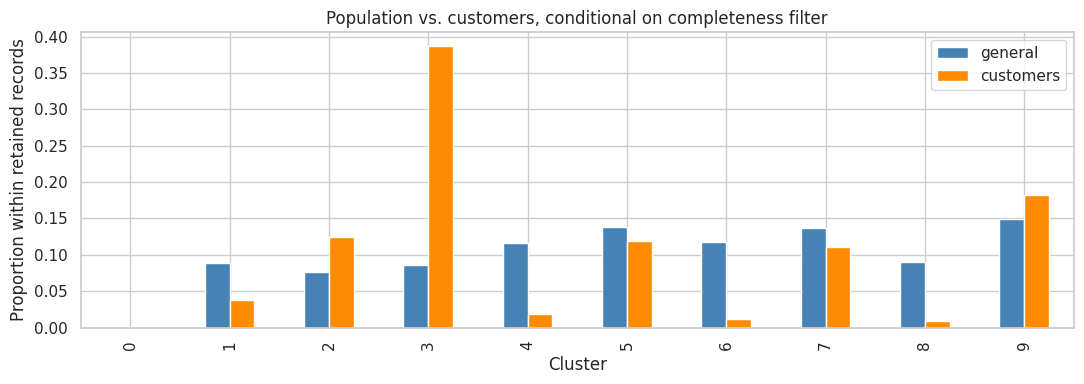

,general,customers,difference,lift
3,0.085393,0.386580,0.301187,4.527087
2,0.076329,0.124692,0.048363,1.633606
9,0.149758,0.182494,0.032736,1.218594
0,0.000787,0.001002,0.000215,1.273273
5,0.137596,0.119365,-0.018231,0.867502
7,0.136878,0.110122,-0.026757,0.804523
1,0.089049,0.037474,-0.051575,0.420825
8,0.090209,0.008728,-0.081481,0.096755
4,0.115984,0.018247,-0.097737,0.157320
6,0.118016,0.011297,-0.106720,0.095720


,general,customers
Cluster 0,0.000705,0.000741
Cluster 1,0.079741,0.027712
Cluster 2,0.068351,0.092209
Cluster 3,0.076467,0.285872
Cluster 4,0.103861,0.013493
Cluster 5,0.123214,0.088269
Cluster 6,0.105681,0.008354
Cluster 7,0.122571,0.081434
Cluster 8,0.080780,0.006454
Cluster 9,0.134105,0.134953


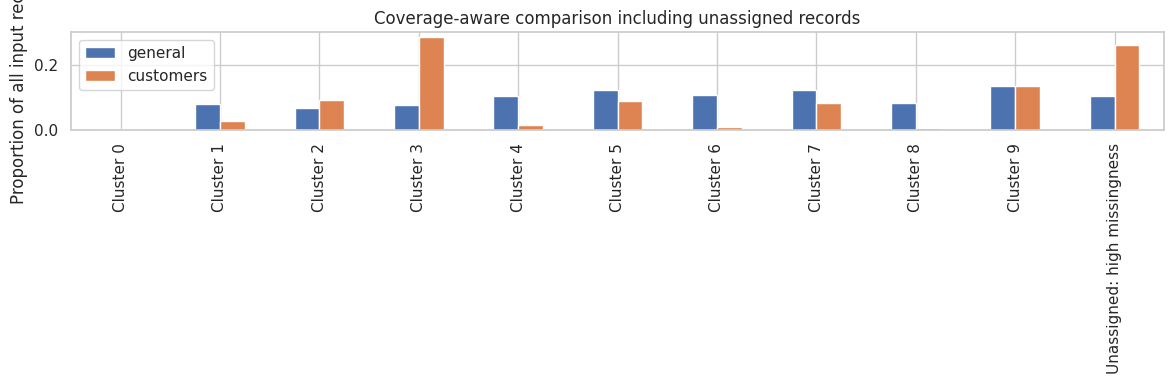

In [41]:
general_counts = pd.Series(general_clusters).value_counts().reindex(
    range(N_CLUSTERS), fill_value=0)
customer_counts = pd.Series(customer_clusters).value_counts().reindex(
    range(N_CLUSTERS), fill_value=0)
comparison = pd.DataFrame({
    'general': general_counts / len(general_clusters),
    'customers': customer_counts / len(customer_clusters)
})
comparison['difference'] = comparison['customers'] - comparison['general']
comparison['lift'] = comparison['customers'].div(
    comparison['general'].replace(0, np.nan))
comparison.plot.bar(y=['general', 'customers'], figsize=(11, 4),
                    color=['steelblue', 'darkorange'])
plt.ylabel('Proportion within retained records')
plt.xlabel('Cluster')
plt.title('Population vs. customers, conditional on completeness filter')
plt.tight_layout()
plt.show()
display(comparison.sort_values('difference', ascending=False))

# A second view uses all input records as the denominator.
all_record_comparison = pd.DataFrame({
    'general': general_counts / len(azdias_raw),
    'customers': customer_counts / len(customers)
})
all_record_comparison.index = all_record_comparison.index.map(
    lambda c: f'Cluster {c}')
all_record_comparison.loc['Unassigned: high missingness'] = [
    len(azdias_high) / len(azdias_raw), len(customers_high) / len(customers)
]
assert np.allclose(all_record_comparison.sum(), 1)
display(all_record_comparison)
all_record_comparison.plot.bar(figsize=(12, 4))
plt.ylabel('Proportion of all input records')
plt.title('Coverage-aware comparison including unassigned records')
plt.tight_layout()
plt.show()


In [42]:
# Also compare how many rows were set aside for having too much missing data —
# this group effectively acts as an extra 'unknown' segment.
print('high-missing rows, general population: {:.1%}'.format(
    len(azdias_high) / (len(azdias_high) + len(azdias_clean))))
print('high-missing rows, customers:          {:.1%}'.format(
    len(customers_high) / (len(customers_high) + len(customers_clean))))

high-missing rows, general population: 10.5%
high-missing rows, customers:          26.1%


In [43]:
def describe_cluster(cluster_id, n_features=12):
    z = cluster_z.loc[cluster_id].sort_values()
    extremes = z.abs().nlargest(n_features).index
    table = pd.DataFrame({
        'cluster_mean': cluster_means.loc[cluster_id, extremes],
        'population_mean': population_means[extremes],
        'standardized_difference': z[extremes],
        'interpretation': [
            feature_meaning(f, z[f] > 0) for f in extremes
        ]
    })
    print(f'Cluster {cluster_id}: empirical means in the imputed population')
    display(table)
    return z


In [44]:
# What kinds of people are part of a cluster that is overrepresented in the
# customer data compared to the general population?
over_cluster = comparison['difference'].idxmax()
print('Most OVER-represented cluster: {} '
      '(customers {:.1%} vs. general {:.1%})\n'.format(
          over_cluster, comparison.loc[over_cluster, 'customers'],
          comparison.loc[over_cluster, 'general']))
_ = describe_cluster(over_cluster)

Most OVER-represented cluster: 3 (customers 38.7% vs. general 8.5%)

Cluster 3: empirical means in the imputed population


,cluster_mean,population_mean,standardized_difference,interpretation
LP_STATUS_GROB_5.0,0.635152,0.139805,1.428399,greater share of top earners
GREEN_AVANTGARDE,0.756827,0.219562,1.297900,greater green-avantgarde share
FINANZ_MINIMALIST,4.761816,3.058916,1.236157,weaker low-financial-interest affinity
HH_EINKOMMEN_SCORE,2.527931,4.413465,-1.220217,higher household income
ZABEOTYP_1,0.580537,0.154696,1.177608,greater share of green energy-consumption type
ANREDE_KZ,1.001585,1.521486,-1.040764,greater male-coded share
SEMIO_VERT,6.173033,4.277350,0.974351,weaker dreamful affinity
SEMIO_KAEM,2.476030,4.294274,-0.973554,stronger combative affinity
FINANZ_ANLEGER,1.422838,2.840956,-0.962885,stronger investing affinity
KBA05_ANTG1,2.661859,1.469398,0.868867,greater 1-2-family building share


In [45]:
# What kinds of people are part of a cluster that is underrepresented in the
# customer data compared to the general population?
under_cluster = comparison['difference'].idxmin()
print('Most UNDER-represented cluster: {} '
      '(customers {:.1%} vs. general {:.1%})\n'.format(
          under_cluster, comparison.loc[under_cluster, 'customers'],
          comparison.loc[under_cluster, 'general']))
_ = describe_cluster(under_cluster)

Most UNDER-represented cluster: 6 (customers 1.1% vs. general 11.8%)

Cluster 6: empirical means in the imputed population


,cluster_mean,population_mean,standardized_difference,interpretation
FINANZ_MINIMALIST,1.220693,3.058916,-1.334390,stronger low-financial-interest affinity
SEMIO_RAT,6.028561,3.893826,1.291464,weaker rational affinity
FINANZTYP_1,0.787026,0.247062,1.251935,greater share of low financial interest (MINIM...
FINANZ_SPARER,4.363922,2.716050,1.109611,weaker money-saving affinity
SEMIO_VERT,2.208186,4.277350,-1.063518,stronger dreamful affinity
LP_STATUS_GROB_1.0,0.926305,0.404377,1.063485,greater share of low-income earners
SEMIO_KAEM,6.240665,4.294274,1.042169,weaker combative affinity
SEMIO_TRADV,5.420014,3.724242,0.960483,weaker traditional affinity
SEMIO_PFLICHT,5.918766,4.184520,0.935470,weaker dutiful affinity
ANREDE_KZ,1.979551,1.521486,0.916976,greater female-coded share


#### Discussion 3.3: Compare Customer Data to Demographics Data

The following generated discussion names the most over- and under-represented
segments for **this run**, gives their proportions and lift, and translates
their strongest measured attributes using the dictionary. Profiles use actual
means of the assigned population records after imputation, not potentially
out-of-range reconstructed PCA centroids. Means of ordinal codes summarize
directions, not exact ages or income amounts. Binary means represent shares.

Differences are descriptive, not causal evidence or purchase-probability
estimates. Customers and the general-population file have different sampling
and completeness patterns. The all-record table keeps the unassigned group in
view. High-lift segments are candidates for further campaign testing, not a
guarantee of profitability; underrepresented segments are not necessarily
unreachable. No blanket claim about older/rural/conservative customers is made
unless their measured attributes actually support it.


In [46]:
for title, cluster_id in [('Overrepresented', over_cluster),
                          ('Underrepresented', under_cluster)]:
    row = comparison.loc[cluster_id]
    top = cluster_z.loc[cluster_id].abs().nlargest(5).index
    traits = '; '.join(
        f'**{feature_meaning(f, cluster_z.loc[cluster_id, f] > 0)}** '
        f'(`{f}`, standardized difference '
        f'{cluster_z.loc[cluster_id, f]:+.2f})'
        for f in top
    )
    display(Markdown(
        f'### {title}: cluster {cluster_id}\n'
        f'**{row["customers"]:.1%} of retained customers** versus '
        f'**{row["general"]:.1%} of retained population**, a difference of '
        f'**{100 * row["difference"]:+.1f} percentage points** and '
        f'**{row["lift"]:.2f}x lift**. Distinctive population profile: {traits}.'
    ))
display(Markdown(
    f'**Coverage limitation:** {len(azdias_high) / len(azdias_raw):.1%} of '
    f'population records and {len(customers_high) / len(customers):.1%} of '
    'customers are unassigned because of high missingness. The within-retained '
    'comparison cannot be generalized to those excluded records. '
    'The all-record chart reports their separate shares explicitly.'
))
popular = comparison.index[comparison['difference'] > 0].tolist()
unpopular = comparison.index[comparison['difference'] < 0].tolist()
display(Markdown(
    f'**Marketing interpretation:** clusters {popular} are overrepresented '
    f'among retained customers; clusters {unpopular} are underrepresented. '
    'Use the measured profiles above to develop hypotheses for controlled '
    'campaign tests. These descriptive segments do not establish expected '
    'return on investment or justify individual-level targeting decisions.'
))


### Overrepresented: cluster 3
**38.7% of retained customers** versus **8.5% of retained population**, a difference of **+30.1 percentage points** and **4.53x lift**. Distinctive population profile: **greater share of top earners** (`LP_STATUS_GROB_5.0`, standardized difference +1.43); **greater green-avantgarde share** (`GREEN_AVANTGARDE`, standardized difference +1.30); **weaker low-financial-interest affinity** (`FINANZ_MINIMALIST`, standardized difference +1.24); **higher household income** (`HH_EINKOMMEN_SCORE`, standardized difference -1.22); **greater share of green energy-consumption type** (`ZABEOTYP_1`, standardized difference +1.18).

### Underrepresented: cluster 6
**1.1% of retained customers** versus **11.8% of retained population**, a difference of **-10.7 percentage points** and **0.10x lift**. Distinctive population profile: **stronger low-financial-interest affinity** (`FINANZ_MINIMALIST`, standardized difference -1.33); **weaker rational affinity** (`SEMIO_RAT`, standardized difference +1.29); **greater share of low financial interest (MINIMALIST)** (`FINANZTYP_1`, standardized difference +1.25); **weaker money-saving affinity** (`FINANZ_SPARER`, standardized difference +1.11); **stronger dreamful affinity** (`SEMIO_VERT`, standardized difference -1.06).

**Coverage limitation:** 10.5% of population records and 26.1% of customers are unassigned because of high missingness. The within-retained comparison cannot be generalized to those excluded records. The all-record chart reports their separate shares explicitly.

**Marketing interpretation:** clusters [0, 2, 3, 9] are overrepresented among retained customers; clusters [1, 4, 5, 6, 7, 8] are underrepresented. Use the measured profiles above to develop hypotheses for controlled campaign tests. These descriptive segments do not establish expected return on investment or justify individual-level targeting decisions.

## Reproducibility and HTML submission

Run **Restart Kernel and Run All** in a Python environment with `numpy`,
`pandas`, `scikit-learn`, `matplotlib`, `seaborn`, and `IPython`, with all four
supplied data/dictionary files beside this notebook. Save after execution so
the numerical findings, generated interpretations, and plots are persisted.
Category modes, scaling, PCA and k-means are fitted only on the population.

Export the **executed, saved** notebook from Jupyter's HTML export menu, or use:

```sh
jupyter nbconvert --to html Identify_Customer_Segments.ipynb
```

Inspect the resulting HTML to confirm that the plots, three component
interpretations, cluster trade-off, profiles, and coverage limitations appear.
Do not submit a report with outputs from a previous preprocessing version.
